In [159]:
import os
import numpy as np
import pandas as pd
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine
import os, json
from dotenv import load_dotenv
from openai import OpenAI

In [2]:
load_dotenv(find_dotenv(usecwd=True))   

True

In [97]:
PG_URL = (
    f"postgresql+psycopg2://{os.environ['POSTGRES_USER']}:{os.environ['POSTGRES_PASSWORD']}"
    f"@{os.getenv('POSTGRES_HOST', 'localhost')}:{os.getenv('POSTGRES_PORT', '5432')}"
    f"/{os.environ['POSTGRES_DB']}"
)
pg = create_engine(PG_URL)
pd.set_option("display.width", 200)
print("Қосылды")

Қосылды


In [471]:
df = pd.read_sql(""" 
    SELECT cl.line_id, cl.contract_id, cl.lot_id, cl.plan_id,
       cl.customer_bin, cl.supplier_bin,
       cl.year, cl.sign_date, c.plan_exec_date, c.fact_exec_date, cl.status,
       cl.fact_trade_method, cl.is_single_source,
       cl.enstru_code, cl.unit_code, cl.item_name_ru,
       cl.quantity, cl.unit_price, cl.total_sum,
       cl.region_code, cl.region_source,
       p.subject_type,
       p.name_ru         AS plan_name,
       p.desc_ru         AS plan_desc,
       p.extra_desc_ru   AS plan_extra_desc,
       l.name_ru         AS lot_name,
       l.description_ru  AS lot_desc
FROM contract_lines cl
JOIN contracts c       ON c.contract_id = cl.contract_id
LEFT JOIN plan_items p ON p.plan_id = cl.plan_id
LEFT JOIN lots l       ON l.lot_id  = cl.lot_id
WHERE cl.price_valid = 1
  AND cl.enstru_code IS NOT NULL AND cl.enstru_code <> ''
  ;
""", pg)

df["subject_type"] = df["subject_type"].astype(str).str.replace(r"\.0$", "", regex=True)
df["unit_code"] = df["unit_code"].astype(str)
df["sign_date"] = pd.to_datetime(df["sign_date"], errors="coerce")
df["month"] = df["sign_date"].dt.to_period("M").dt.to_timestamp()

print("Жолдар:", len(df), "(72 422 болуы керек)")

Жолдар: 77956 (72 422 болуы керек)


In [455]:
print("Жолдар:", len(df))
print("Қайталанған line_id:", df["line_id"].duplicated().sum())
print()

missing = (df.isna().mean() * 100).round(1)
print("Бос мәндер (%):")
print(missing[missing > 0].sort_values(ascending=False))

Жолдар: 77956
Қайталанған line_id: 0

Бос мәндер (%):
lot_name           10.3
lot_desc           10.3
plan_id             7.1
unit_code           7.1
plan_desc           7.1
plan_name           7.1
item_name_ru        7.1
subject_type        7.1
plan_extra_desc     7.1
sign_date           2.0
month               2.0
plan_exec_date      0.1
dtype: float64


In [456]:
print("Күні жоқ жолдар:", df["sign_date"].isna().sum())
print("Ең ерте:", df["sign_date"].min(), "| Ең кеш:", df["sign_date"].max())
print()
print("Жылдар бойынша:")
print(df["year"].value_counts().sort_index())
print()
after = df["month"] > pd.Timestamp("2026-09-01")
print("ИПЦ жарияланбаған айлардағы жолдар (2026-09-тан кейін):", after.sum())

Күні жоқ жолдар: 1553
Ең ерте: 2024-01-03 09:13:37 | Ең кеш: 2026-10-23 06:51:02

Жылдар бойынша:
year
2024    28194
2025    26516
2026    23246
Name: count, dtype: int64

ИПЦ жарияланбаған айлардағы жолдар (2026-09-тан кейін): 1416


In [457]:
print(df["subject_type"].value_counts(dropna=False), "\n")
print(df["status"].value_counts(dropna=False), "\n")
print(df[["quantity", "unit_price", "total_sum"]].describe(
      percentiles=[.01, .5, .99]).round(2))

subject_type
1      64349
3       6978
NaN     5534
2       1095
Name: count, dtype: int64 

status
Исполнен                              52677
Действует                             10823
Частично исполнен                      5289
Расторгнут в одностороннем порядке     4379
Расторгнут по соглашению сторон        2356
Не заключен                            1544
Передан.Действует                       410
Изменен                                 248
Создано доп.соглашение                  223
Передача прав                             6
Передан.Исполнен                          1
Name: count, dtype: int64 

          quantity    unit_price     total_sum
count     77956.00  7.795600e+04  7.795600e+04
mean       2044.84  2.623469e+06  3.322172e+06
std      140700.62  1.749036e+08  1.752102e+08
min           0.00  1.000000e+00  1.000000e-02
1%            1.00  1.800000e+01  1.299550e+03
50%          10.00  5.432000e+03  1.200000e+05
99%       16598.88  1.805084e+07  2.655399e+07
max    36627

In [109]:
def filled(s):
    return s.fillna("").astype(str).str.strip().ne("").mean()

desc_cols = ["plan_name", "plan_desc", "plan_extra_desc", "lot_name", "lot_desc"]
for c in desc_cols:
    print(f"{c:16} толтырылған: {filled(df[c]):.1%}")

# Бір кодтың ішінде сипаттама әртүрлі ме (яғни еркін мәтін бе)?
by_code = df.groupby("enstru_code").agg(
    lines=("line_id", "size"),
    **{f"{c}_n": (c, "nunique") for c in desc_cols},
)
multi = by_code[by_code["lines"] >= 3]
print(f"\nКемінде 3 жолы бар кодтар: {len(multi)}")
for c in desc_cols:
    print(f"  {c:16} әртүрлі: {(multi[f'{c}_n'] > 1).mean():.1%}")

plan_name        толтырылған: 92.9%
plan_desc        толтырылған: 92.9%
plan_extra_desc  толтырылған: 92.9%
lot_name         толтырылған: 89.7%
lot_desc         толтырылған: 89.7%

Кемінде 3 жолы бар кодтар: 4660
  plan_name        әртүрлі: 0.1%
  plan_desc        әртүрлі: 0.3%
  plan_extra_desc  әртүрлі: 96.9%
  lot_name         әртүрлі: 59.5%
  lot_desc         әртүрлі: 59.7%


In [110]:
pd.set_option("display.max_colwidth", 80)
df.loc[df["enstru_code"] == "325013.630.000004",
       ["unit_price", "quantity", "plan_extra_desc", "lot_desc"]].sort_values("unit_price")

,unit_price,quantity,plan_extra_desc,lot_desc
32430,204.8,2600.0,"Соединение Люэр лок совместимо со всеми шприцами для насосов, устойчивость к...",для инфузионного насоса
72333,207.0,3000.0,"Удлинитель к нососу инфузионному шприцевому, длтна 150 мл одноразовый",для инфузионного насоса
32438,247.0,1500.0,"Соединение Люэр лок совместимо со всеми шприцами для насосов, устойчивость к...",для инфузионного насоса
484,250.0,2815.0,"Удлинитель к насосу инфузионному шприцевому, длина 200см",для инфузионного насоса
72410,285.0,3000.0,"Удлинитель к насосу инфузионному шприцевому, длина 200см",для инфузионного насоса
61467,117200.0,10.0,Набор реагентов Панели брейкпойнт комбинированные для идентификации и опреде...,Реагенты и расходные материалы для анализатора MicroScan Walk Away 40 Plus
47733,162000.0,7.0,Набор реагентов Панели комбинированные для идентификации и определения чувст...,Реагенты и расходные материалы для анализатора MicroScan Walk Away 40 Plus
61466,162300.0,10.0,Набор реагентов Панели комбинированные для идентификации и определения чувст...,Реагенты и расходные материалы для анализатора MicroScan Walk Away 40 Plus
66437,203840.0,5.0,"Педиатрическая панель для определения комплекса аллергенов в одной панели, в...",для инфузионного насоса
67694,203840.0,5.0,"Педиатрическая панель для определения комплекса аллергенов в одной панели, в...",для инфузионного насоса


In [111]:
# 1) Күні жоқ жолдар = «Не заключен» бе?
print(pd.crosstab(df["status"] == "Не заключен", df["sign_date"].isna(),
                  rownames=["Не заключен"], colnames=["күні жоқ"]), "\n")

# 2) Өлшем бірлігі жоқ жолдар = жоспармен байланыспаған жолдар ма?
print(pd.crosstab(df["plan_id"].isna(), df["unit_code"].isna(),
                  rownames=["plan_id жоқ"], colnames=["unit_code жоқ"]), "\n")

# 3) Сан
print("quantity <= 0:", (df["quantity"] <= 0).sum())
print("0 < quantity < 1:", ((df["quantity"] > 0) & (df["quantity"] < 1)).sum())

күні жоқ     False  True 
Не заключен              
False        76403      9
True             0   1544 

unit_code жоқ  False  True 
plan_id жоқ                
False          72422      0
True               0   5534 

quantity <= 0: 0
0 < quantity < 1: 156


In [135]:
tovars = df[
    (df["status"] != "Не заключен")
    & df["sign_date"].notna()
    & df["unit_code"].notna()
    & (df["quantity"] > 0)
    & df["subject_type"].isin(["1"])          # тауар, қызмет
].copy() 
tovars["gk"] = tovars["enstru_code"] + "|" + tovars["unit_code"]
tovars.head(2)

,line_id,contract_id,lot_id,plan_id,customer_bin,supplier_bin,year,sign_date,status,fact_trade_method,...,region_code,region_source,subject_type,plan_name,plan_desc,plan_extra_desc,lot_name,lot_desc,month,gk
0,53304541,23464538,37988626,80099759.0,020440003656,030219501483,2025,2025-09-26 11:33:56,Исполнен,Запрос ценовых предложений,...,710000000,lot,1,Фурнитура,"для окон, с петлями и ручками",Редуктор Камерный для алюминиевых Витражей производство Schuco (правый – артикул 243034). Каменрный редуктор 23 мм. ...,Стройматериалы (Ремонтно - строительная служба),Стройматериалы (Ремонтно - строительная служба),2025-09-01,222926.150.000002|796
1,53360431,23494607,38094909,80100531.0,990740002243,080840001457,2025,2025-09-23 11:35:23,Частично исполнен,Из одного источника по несостоявшимся закупкам,...,710000000,lot,1,Материал специальный,медицинский,"Нить стерильная хирургическая, окрашенная, 1(4), 150 см",Изделия медицинского назначения,Изделия медицинского назначения,2025-09-01,325050.900.000006|796


In [136]:
tovars.shape

(62980, 27)

In [344]:
inflations=pd.read_excel('../src/ИПЦ и его составляющие.xlsx',skiprows=0)
inflations = inflations.rename(columns={inflations.columns[0]: "month"})
mom_cols = list(inflations.columns[1:5])          # сіздің төрт бағаныңыз

inflations[mom_cols] = inflations[mom_cols].apply(pd.to_numeric, errors="coerce")
inflations = (inflations.dropna(subset=["month"])                  # NaT жолдары (0, 1)
          .dropna(subset=mom_cols, how="all")        # әлі жарияланбаған айлар (қазан–желтоқсан)
          .sort_values("month")
          .reset_index(drop=True))

BASE = pd.Timestamp("2026-10-01")

for col in mom_cols:
    idx = (inflations[col] / 100).cumprod()                 # 2021 жылдың желтоқсанынан бергі жинақталған индекс
    base_val = idx[inflations["month"] == BASE].iloc[0]
    inflations[f"{col} - 2026-10"] = base_val / idx         # айдың бағасын 2026-09 бағасына аударатын коэффициент

# Әр бағанның жанына оның жұбын қоямыз
order = ["month"] + [c for col in mom_cols for c in (col, f"{col} - 2026-10")]
inflations = inflations[order]
inflations.round(4).tail(3)

C:\Users\Фатима\AppData\Local\Temp\ipykernel_25328\240550641.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  inflations.round(4).tail(3)


,month,К предыдущему месяцу товары и услуги,К предыдущему месяцу товары и услуги - 2026-10,К предыдущему месяцу товары продоволь-ственные,К предыдущему месяцу товары продоволь-ственные - 2026-10,К предыдущему месяцу товары непродо-вольственные,К предыдущему месяцу товары непродо-вольственные - 2026-10,К предыдущему месяцу платные услуги,К предыдущему месяцу платные услуги - 2026-10
55,2026-08-01,100.6,1.012,99.9,0.998,100.8,1.0221,101.2,1.0201
56,2026-09-01,100.6,1.006,99.9,0.999,101.1,1.0110,101.0,1.0100
57,2026-10-01,100.6,1.000,99.9,1.000,101.1,1.0000,101.0,1.0000


In [137]:
tovars["month"] = pd.to_datetime(tovars["sign_date"]).dt.to_period("M").dt.to_timestamp()

tovars = tovars.merge(
    inflations[["month", "К предыдущему месяцу товары и услуги - 2026-10"]],
    on="month",
    how="left",
)
tovars['unit_price_st'] = tovars['unit_price']*tovars['К предыдущему месяцу товары и услуги - 2026-10']
tovars.head(2)

,line_id,contract_id,lot_id,plan_id,customer_bin,supplier_bin,year,sign_date,status,fact_trade_method,...,subject_type,plan_name,plan_desc,plan_extra_desc,lot_name,lot_desc,month,gk,К предыдущему месяцу товары и услуги - 2026-10,unit_price_st
0,53304541,23464538,37988626,80099759.0,020440003656,030219501483,2025,2025-09-26 11:33:56,Исполнен,Запрос ценовых предложений,...,1,Фурнитура,"для окон, с петлями и ручками",Редуктор Камерный для алюминиевых Витражей производство Schuco (правый – артикул 243034). Каменрный редуктор 23 мм. ...,Стройматериалы (Ремонтно - строительная служба),Стройматериалы (Ремонтно - строительная служба),2025-09-01,222926.150.000002|796,1.10035,26428.033949
1,53360431,23494607,38094909,80100531.0,990740002243,080840001457,2025,2025-09-23 11:35:23,Частично исполнен,Из одного источника по несостоявшимся закупкам,...,1,Материал специальный,медицинский,"Нить стерильная хирургическая, окрашенная, 1(4), 150 см",Изделия медицинского назначения,Изделия медицинского назначения,2025-09-01,325050.900.000006|796,1.10035,2222.706386


In [125]:
pd.set_option("display.max_colwidth", 120)

def show_group(code, unit="796", n=15):
    g = tovars[(tovars["enstru_code"] == code) & (tovars["unit_code"] == unit)]
    g = g.sort_values("unit_price")
    idx = np.linspace(0, len(g) - 1, min(n, len(g))).astype(int)   # арзаннан қымбатқа біркелкі іріктеме
    return g.iloc[idx][["unit_price", "quantity", "plan_extra_desc", "lot_desc"]]

show_group("325013.630.000004")      # Панель передняя

,unit_price,quantity,plan_extra_desc,lot_desc
28720,204.8,2600.0,"Соединение Люэр лок совместимо со всеми шприцами для насосов, устойчивость к давлению до 4 бар, материал ПВХ, длина ...",для инфузионного насоса
62894,207.0,3000.0,"Удлинитель к нососу инфузионному шприцевому, длтна 150 мл одноразовый",для инфузионного насоса
28728,247.0,1500.0,"Соединение Люэр лок совместимо со всеми шприцами для насосов, устойчивость к давлению до 4 бар, материал ПВХ, длина ...",для инфузионного насоса
420,250.0,2815.0,"Удлинитель к насосу инфузионному шприцевому, длина 200см",для инфузионного насоса
62968,285.0,3000.0,"Удлинитель к насосу инфузионному шприцевому, длина 200см",для инфузионного насоса
29233,250825.0,18.0,"Педиатрическая панель для определения комплекса аллергенов в одной панели, в комплекте всмпоготельный раствор, 16 ст...",для инфузионного насоса
15946,297203.0,25.0,"Ингаляционная панель для определения комплекса аллергенов, 16 стрип- полосок",для инфузионного насоса
244,297203.0,8.0,"Ингаляционная панель для определения комплекса аллергенов, 16 стрип- полосок",для инфузионного насоса
29347,341738.0,24.0,"Ингаляционная панель для определения комплекса аллергенов в одной панели, в комплекте вспомогательный раствор, 16 ст...",для инфузионного насоса


In [138]:
tovars['gk'].nunique() 

11020

In [122]:
price_col = "unit_price_st"
gk_medians = tovars.groupby("gk")[price_col].median()

gk_deviations = tovars[["gk", price_col]].copy()
gk_deviations["gk_median"] = gk_deviations["gk"].map(gk_medians)
gk_deviations = gk_deviations[gk_deviations["gk_median"] > 0].copy()
gk_deviations["deviation_ratio"] = gk_deviations[price_col] / gk_deviations["gk_median"]
gk_deviations["deviation_pct"] = gk_deviations["deviation_ratio"] - 1

gk_deviation_stats = gk_deviations.groupby("gk")["deviation_pct"].describe()
gk_extreme_observations = gk_deviations[
    (gk_deviations["deviation_ratio"] > 10) 
    | (gk_deviations["deviation_ratio"] < 0.1)
]
gk_types_over_10 = gk_extreme_observations["gk"].drop_duplicates().tolist()

print("gk types with observations more than 10x from median:", len(gk_types_over_10))
print(gk_types_over_10)
gk_deviation_stats.sort_values(by='max',ascending=False)

gk types with observations more than 10x from median: 972
['325013.110.000000|796', '212024.200.000002|796', '266012.100.000000|796', '325022.900.000001|796', '325013.790.000001|796', '325013.100.000005|796', '281413.900.000096|796', '204132.590.000008|796', '325013.110.000002|796', '274011.000.000000|796', '265170.150.000001|796', '325013.100.000064|796', '325013.170.000006|796', '222929.900.000122|796', '204219.100.000000|796', '293220.990.000031|796', '325013.630.000004|796', '212023.400.000026|778', '205952.100.000297|704', '265182.500.000120|778', '274039.900.000052|796', '274022.900.000000|796', '274014.600.000000|796', '151212.900.000094|796', '325013.170.000001|796', '212013.990.000509|872', '325013.100.000081|796', '205959.630.000026|796', '205952.100.000297|778', '222922.900.000004|796', '264042.700.000008|796', '212013.990.000113|796', '325050.900.000006|796', '325013.100.000062|796', '222213.000.000024|796', '293123.100.000018|796', '282982.500.000070|778', '289422.300.0000

,count,mean,std,min,25%,50%,75%,max
gk,,,,,,,,
325013.630.000007|796,13.0,891.120503,3128.905066,-0.985444,-0.967523,0.000000e+00,30.609959,11303.199307
222929.900.000069|796,40.0,443.502241,1821.312514,-0.435745,-0.161096,5.551115e-17,8.253814,10782.135932
325013.100.000081|796,15.0,468.684553,1745.967555,-0.835417,-0.430326,0.000000e+00,27.234799,6778.650347
325011.500.000007|796,20.0,309.887149,1194.148535,-0.607932,-0.552319,0.000000e+00,33.911629,5361.625551
259411.900.000164|796,45.0,74.725666,484.544215,-0.488703,-0.214988,0.000000e+00,0.581013,3251.370402
...,...,...,...,...,...,...,...,...
011360.400.000000|166,1.0,0.000000,NaN,0.000000,0.000000,0.000000e+00,0.000000,0.000000
011380.100.000000|796,1.0,0.000000,NaN,0.000000,0.000000,0.000000e+00,0.000000,0.000000
329959.900.000099|796,1.0,0.000000,NaN,0.000000,0.000000,0.000000e+00,0.000000,0.000000


In [128]:
tovars.columns

Index(['line_id', 'contract_id', 'lot_id', 'plan_id', 'customer_bin', 'supplier_bin', 'year', 'sign_date', 'status', 'fact_trade_method', 'is_single_source', 'enstru_code', 'unit_code',
       'item_name_ru', 'quantity', 'unit_price', 'total_sum', 'region_code', 'region_source', 'subject_type', 'plan_name', 'plan_desc', 'plan_extra_desc', 'lot_name', 'lot_desc', 'month', 'gk',
       'К предыдущему месяцу товары и услуги - 2026-09', 'unit_price_st', 'К предыдущему месяцу товары и услуги - 2026-10'],
      dtype='str')

In [139]:
MIN_N = 3                     # шашыраңқылықты өлшеуге ең аз жол саны
MAD_LIMIT = np.log(5) / 2     # әдеттегі ауытқу ≈ 2.24 есе
FAR_LIMIT = 0.20              # медианадан 3 есе алшақ жолдардың үлесі
FAR_MIN_N = 5                 # үлесті есептеуге ең аз жол саны

print("unit_price_st бос немесе ≤ 0:",
      (tovars["unit_price_st"].isna() | (tovars["unit_price_st"] <= 0)).sum())

# 0) Инфляцияға түзетілген бағаның логарифмі
tovars["log_p"] = np.log(tovars["unit_price_st"].where(tovars["unit_price_st"] > 0))

# 1) Топ медианасы және медианадан 10 есе алшақ жолдар
grp = tovars.groupby("gk")["log_p"]
tovars["grp_n"] = grp.transform("count")
tovars["grp_med"] = grp.transform("median")
dev = tovars["log_p"] - tovars["grp_med"]

tovars["data_issue"] = None
tovars.loc[(tovars["grp_n"] >= MIN_N) & (dev >=  np.log(10)), "data_issue"] = "extreme_high"
tovars.loc[(tovars["grp_n"] >= MIN_N) & (dev <= -np.log(10)), "data_issue"] = "extreme_low"

# 2) Таза жолдар: медиана және MAD
clean = tovars[tovars["data_issue"].isna()]
med_clean = clean.groupby("gk")["log_p"].median()
abs_dev_clean = (clean["log_p"] - clean["gk"].map(med_clean)).abs()

stats = abs_dev_clean.groupby(clean["gk"]).agg(n_clean="count", mad="median")
stats["med_clean"] = med_clean
stats["mad_factor"] = np.exp(stats["mad"])

# 3) Алшақ жолдардың үлесі: БАРЛЫҚ жолдардан (шеткілерін қоса), таза медианаға қатысты
all_dev = (tovars["log_p"] - tovars["gk"].map(med_clean)).abs()
far_flag = (all_dev > np.log(3)).where(all_dev.notna())
far = far_flag.groupby(tovars["gk"]).agg(n_all="count", far_share="mean")
stats = stats.join(far)

# 4) Екі топ: біртекті / әртекті (+ өлшеуге дерегі аз)
by_mad = stats["mad"] > MAD_LIMIT
by_far = (stats["n_all"] >= FAR_MIN_N) & (stats["far_share"] > FAR_LIMIT)

stats["tier"] = np.select(
    [stats["n_all"] < MIN_N,                                   # жалпы жол аз
     by_mad | by_far | (stats["n_clean"] < MIN_N)],            # шашыраңқы, алшақтар көп немесе таза жол аз қалды
    ["small", "heterogeneous"],
    default="homogeneous",
)
stats["het_reason"] = np.select(
    [stats["tier"] != "heterogeneous", stats["n_clean"] < MIN_N, by_mad & by_far, by_mad],
    ["", "extremes", "mad+far", "mad"],
    default="far",
)

# 5) Әр жолға тобының нәтижесін қосу
cols = ["n_clean", "n_all", "med_clean", "mad", "mad_factor", "far_share", "tier", "het_reason"]
tovars = tovars.drop(columns=cols, errors="ignore").merge(
    stats[cols], left_on="gk", right_index=True, how="left")
tovars["tier"] = tovars["tier"].fillna("small")

print(tovars["data_issue"].value_counts())

unit_price_st бос немесе ≤ 0: 0
data_issue
extreme_high    1218
extreme_low     1051
Name: count, dtype: int64


In [145]:
tovars['tier'].value_counts(normalize=True)*100

tier
homogeneous      60.528739
heterogeneous    26.486186
small            12.985075
Name: proportion, dtype: float64

### Homogeneous tovars

In [146]:
homo_tovar=tovars[tovars['tier']=='homogeneous']
homo_tovar.head(2)

,line_id,contract_id,lot_id,plan_id,customer_bin,supplier_bin,year,sign_date,status,fact_trade_method,...,n_clean,n_all,med_clean,mad,mad_factor,far_share,tier,het_reason,is_extreme,ratio
3,53195022,23406596,37874292,80106204.0,990740002243,110340014141,2025,2025-09-05 16:50:17,Частично исполнен,Из одного источника по несостоявшимся закупкам,...,14.0,15.0,10.499498,0.485786,1.625452,0.133333,homogeneous,,False,1.260363
4,53726220,23678248,33979413,80094726.0,990740002243,100740003238,2025,2025-10-31 14:55:20,Исполнен,Из одного источника по несостоявшимся закупкам,...,6.0,6.0,7.386462,0.151672,1.163779,0.0,homogeneous,,False,1.356735


In [199]:
def fair_price_for(line_id, df=None, drop_own_customer=False, drop_own_contract=True, min_n=5, min_cust=2):
    """
    line_id шарт жолына сай жолдардың gk-ларын табады және әр gk үшін
    сол gk-ның шартқа сай КЕЛМЕЙТІН таза жолдарынан медиана есептейді.
    """
    if df is None:
        df = tovars[tovars["tier"] == "homogeneous"]

    # 1) Шартты маскаға айналдыру
    m=df["line_id"] == line_id

    target = df[m].rename(columns={"unit_price_st": "target_unit_price_st","quantity":"target_quantity"})
    if target.empty:
        print("Мұндай line_id жоқ.")
        return pd.DataFrame()

    # 2) Эталон: сол gk-лардың шартқа сай келмейтін, data_issue емес жолдары
    pool = df[df["gk"].isin(target["gk"].unique()) & ~m & df["data_issue"].isna() & (df["unit_price_st"] > 0) & (df["quantity"] > 0)]
    if drop_own_customer:
        pool = pool[~pool["customer_bin"].isin(target["customer_bin"])]
    if drop_own_contract:
        pool = pool[~pool["contract_id"].isin(target["contract_id"])]

    # 3) Әр gk бойынша салыстыру
    r = pool.groupby("gk").agg(
        ref_n=("unit_price_st", "size"),
        ref_customers=("customer_bin", "nunique"),
        fair_price_median=("unit_price_st", "median"),
        fair_price_mean=("unit_price_st", "mean"),
    )
    res = target.join(r, on="gk")
    res[["ref_n", "ref_customers"]] = res[["ref_n", "ref_customers"]].fillna(0).astype(int)
    res["deviation_median"] = (res["target_unit_price_st"] / res["fair_price_median"] - 1)*100
    res["deviation_mean"] = (res["target_unit_price_st"] / res["fair_price_mean"] - 1)*100
    res["data_enough"] = (res["ref_n"] >= min_n) & (res["ref_customers"] >= min_cust)

    return res

In [194]:
homo_tovar.groupby('gk').size().sort_values(ascending=False)

gk
265152.790.000057|778    338
172312.700.000031|796    307
282530.100.000002|796    206
205912.000.000008|796    192
222925.700.000027|796    186
                        ... 
108313.200.000000|796      3
108312.700.000000|166      3
265153.900.000091|778      3
265153.900.000080|796      3
265153.900.000065|796      3
Length: 3839, dtype: int64

In [200]:
homo_tovar[homo_tovar['gk']=='265152.790.000057|778']['line_id']

224      53480920
580      53480916
592      53480918
618      53480919
627      53480911
           ...   
60873    53480977
60879    53480981
60898    53480982
62450    53808448
62717    48499861
Name: line_id, Length: 338, dtype: int64

In [ ]:
fair_price_for(line_id=53480920)

,line_id,contract_id,lot_id,plan_id,customer_bin,supplier_bin,year,sign_date,status,fact_trade_method,...,het_reason,is_extreme,ratio,ref_n,ref_customers,fair_price_median,fair_price_mean,deviation_median,deviation_mean,data_enough
224,53480920,23554778,33432373,80053463.0,990740002243,021240005426,2025,2025-10-03 14:06:03,Частично исполнен,Открытый конкурс,...,,False,1.078111,288,2,56550.981569,89922.956832,8.420785,-31.816057,True


In [232]:
limit=10
def find_overpriced_by_enstru(enstru_code, threshold=0.30, limit=limit):
    code = str(enstru_code).strip()
    ids = homo_tovar.loc[homo_tovar['enstru_code'].astype(str).str.strip() == code, "line_id"]
    if ids.empty:
        return {"status": "not_found",
                "message": f"По ЕНСТРУ {code} закупки однородных товаров не найдены."}

    parts = [p for p in (fair_price_for(lid,df=homo_tovar) for lid in ids) if not p.empty]
    checks = pd.concat(parts).sort_values(by=['data_enough','deviation_median'],ascending=False)
    summary = {
        "enstru_code": code,
        "threshold_pct": round(threshold * 100),
        "lines_found": len(checks),
    }

    over = checks[(checks["deviation_mean"] > threshold*100)|(checks["deviation_median"] > threshold*100)]
    summary.update({
        "lines_over": len(over),
        "customers_over": int(over["customer_bin"].nunique()),
    })
    rows = over[["line_id", "contract_id", "customer_bin", "item_name_ru", "unit_code",'unit_price','target_unit_price_st','fair_price_median', 'fair_price_mean', 'deviation_median', 'deviation_mean', 
                 'data_enough']].head(limit)
    return {"status": "ok", "summary": summary,
            "rows": json.loads(rows.to_json(orient="records", force_ascii=False))}

In [239]:
import os, json
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()
PROVIDER = os.getenv("LLM_PROVIDER", "openai")

if PROVIDER == "gemini":
    client = OpenAI(api_key=os.getenv("GEMINI_API_KEY"),
                    base_url="https://generativelanguage.googleapis.com/v1beta/openai/")
    MODEL = os.getenv("LLM_MODEL", "gemini-2.5-flash")
else:
    client = OpenAI()
    MODEL = os.getenv("LLM_MODEL", "gpt-5.4-mini")

OAI_TOOLS = [
    {
        "type": "function",
        "function": {
            "name": "find_overpriced_by_enstru",
            "description": (
                "Находит закупки однородных товаров по коду ЕНСТРУ, у которых цена за единицу "
                "выше справедливой больше чем на порог по средней арифметической ИЛИ по медиане "
                "(достаточно превышения по одной из них). Справедливая цена считается по закупкам "
                "того же товара (тот же ЕНСТРУ и единица измерения) в других договорах, включая "
                "другие договоры того же заказчика. Для сравнения все цены приведены к ценам "
                "октября 2026 года с поправкой на инфляцию.\n"
                "summary: lines_found — сколько строк найдено по коду; lines_over — сколько "
                "превышают порог; customers_over — у скольких заказчиков.\n"
                "rows: unit_price — фактическая цена за единицу на дату закупки; "
                "target_unit_price_st — та же цена в ценах октября 2026; fair_price_median и "
                "fair_price_mean — справедливая цена (медиана и средняя арифметическая) в ценах "
                "октября 2026; deviation_median и deviation_mean — отклонение target_unit_price_st "
                "от справедливой цены в процентах (35.2 означает +35.2%); data_enough — достаточно "
                "ли данных для сравнения (в эталоне не менее 5 строк и не менее 2 заказчиков). "
                "Строки отсортированы: сначала с достаточными данными, затем по убыванию "
                "deviation_median. truncated=true — показаны не все строки."
                "В результате который возвращается из функции,"
                "target_unit_price_st - цена за единицу переведенный на 2026-10 с учетом инфляции, " 
                "data_enough - флаг достаточности контрактных линии для сравнения (больше 5),"
                "deviation_median - отклонение от медианного значения других контрактных линии,"
                "deviation_mean - отклонение от среднего значения других контрактных линии,"
            ),
            "parameters": {
                "type": "object",
                "properties": {
                    "enstru_code": {"type": "string",
                                    "description": "Код ЕНСТРУ как в вопросе, например '222926.150.000002'"},
                    "threshold": {"type": "number",
                                  "description": "Порог отклонения как доля: 30% = 0.30. По умолчанию 0.30"},
                    "limit": {"type": "integer",
                              "description": "Сколько строк вернуть, по умолчанию 20"}
                },
                "required": ["enstru_code"]
            }
        }
    },
]

TOOL_FUNCS = {
    "find_overpriced_by_enstru": find_overpriced_by_enstru,
}

SYSTEM = f"""Ты аналитик государственных закупок Казахстана.
Отвечай на языке вопроса (русский или казахский).
Все числа бери только из результатов инструментов, ничего не придумывай и не пересчитывай.

Как читать результат:
- Давай краткий обзор по важным моментам результата (1–3 предложения)), а не большие таблицы с длинными текстами.
- Отвечай не сухими цифрами с непонятными названиями колонок, а простым языком.
- Сравнивай target_unit_price_st с fair_price_median и fair_price_mean: все три в ценах октября 2026 года.
- unit_price бери как фактическую цену на дату закупки, но не сравнивай её напрямую со справедливой ценой.
- deviation_median и deviation_mean уже в процентах.
- Строки с data_enough=false перечисляй отдельно и помечай как ненадёжные: для них мало данных для сравнения.
- В ответе не используй названия колонок. Ответ должен звучать максимально понятным человеку который не видел таблицы.
- Если полученное значение lines_over будет превышать {limit} , дай знать что записей много, тобой анализировалось только самые сильно отклоняющиеся, 
    а весь список можно будет выгрузить, только коротко несколькими словами.
"""

questions = [
    "Найди закупки с отклонением цены > 30% от средневзвешенной по данному ЕНСТРУ: 265152.790.000057",
    "Покажи закупки по ЕНСТРУ 222926.150.000002, которые дороже медианы более чем на 50%",
    "222926.150.000002 ЕНСТРУ бойынша бағасы 20%-дан асқан сатып алуларды тап",
    "Найди завышенные закупки по ЕНСТРУ 1234324.123412",
    "Привет, что ты умеешь?",
]

for t in OAI_TOOLS:
    assert t["function"]["name"] in TOOL_FUNCS, t["function"]["name"]
print("Инструменты:", list(TOOL_FUNCS), "| модель:", MODEL)

Инструменты: ['find_overpriced_by_enstru'] | модель: gpt-5.4-mini


In [240]:
def run_tool(name, args_json):
    try:
        args = json.loads(args_json or "{}")
        if args.get("threshold", 0) > 1:        # если модель прислала 30 вместо 0.30
            args["threshold"] /= 100
        result = TOOL_FUNCS[name](**args)
    except Exception as e:
        result = {"status": "error", "message": f"{type(e).__name__}: {e}"}
    return json.dumps(result, ensure_ascii=False, default=str)

def ask_agent(question, max_steps=5, verbose=True):
    messages = [{"role": "system", "content": SYSTEM},
                {"role": "user", "content": question}]
    for _ in range(max_steps):
        resp = client.chat.completions.create(model=MODEL, messages=messages, tools=OAI_TOOLS)
        msg = resp.choices[0].message
        if not msg.tool_calls:
            return msg.content
        messages.append(msg.model_dump(exclude_none=True))
        for tc in msg.tool_calls:
            if verbose:
                print(f"🔧 {tc.function.name}({tc.function.arguments})")
            messages.append({"role": "tool", "tool_call_id": tc.id,
                             "content": run_tool(tc.function.name, tc.function.arguments)})
    return "Не удалось получить ответ за допустимое число шагов."

In [244]:
print(ask_agent(questions[0]))

🔧 find_overpriced_by_enstru({"enstru_code":"265152.790.000057","threshold":0.3,"limit":20})
По ЕНСТРУ **265152.790.000057** найдено **345** закупок, из них **115** превышают порог **30%**; такие отклонения встретились у **2 заказчиков**. Вверху списка — самые заметные случаи: цена за единицу в пересчёте на октябрь 2026 года местами выше ориентировочной цены более чем в **4–7 раз**.

Ненадёжных строк здесь нет — по всем показанным записям данных достаточно для сравнения. Если нужно, могу дальше выделить:
- только самые дорогие закупки,
- отдельно по каждому заказчику,
- или выгрузить полный список превышений.


### Heterogeneous tovars

In [286]:
HET=tovars[tovars['tier']=='heterogeneous'].copy()
HET.head(2)

,line_id,contract_id,lot_id,plan_id,customer_bin,supplier_bin,year,sign_date,status,fact_trade_method,...,n_clean,n_all,med_clean,mad,mad_factor,far_share,tier,het_reason,is_extreme,ratio
0,53304541,23464538,37988626,80099759.0,020440003656,030219501483,2025,2025-09-26 11:33:56,Исполнен,Запрос ценовых предложений,...,10.0,11.0,9.989412,0.184936,1.203141,0.272727,heterogeneous,far,False,1.212602
1,53360431,23494607,38094909,80100531.0,990740002243,080840001457,2025,2025-09-23 11:35:23,Частично исполнен,Из одного источника по несостоявшимся закупкам,...,103.0,129.0,9.130727,1.000864,2.720630,0.527132,heterogeneous,mad+far,False,0.146167


In [269]:
HET.shape

(16681, 43)

In [270]:
HET['plan_extra_desc']

0        Редуктор Камерный для алюминиевых Витражей производство Schuco (правый – артикул 243034). Каменрный редуктор 23 мм. ...
1                                                                        Нить стерильная хирургическая, окрашенная, 1(4), 150 см
2                                                                        Нить стерильная хирургическая, окрашенная, 1(4), 150 см
5                                                                           Коронарный управляемый проводник для острых окклюзии
6                                                  Катетер баллонный дилатационный для чрескожной транслюминальной ангиопластики
                                                                  ...                                                           
62963                                            Насадка (180+-10)мм с иглой ,комплект изделий для внутривенного облучения крови
62965                           Марля медицинская, хлопчатобумажная отбеленная, в индивидуальной 

In [350]:
COLOR_RE = re.compile(
    r"^(черн|бел|желт|пурпурн|голуб|син|красн|зелен|сер|коричнев|оранжев|фиолетов|розов|бежев)"
    r"(ый|ий|ой|ая|яя|ое|ее|ые|ие|ого|его|ому|ему|ым|им|ую|юю|ых|их)$"
)
CYR_STOP = {"для", "цвет", "цвета", "цвете"}

def cyr_text(s):
    s = str(s).lower().replace("ё", "е")
    words = re.findall(r"[а-яәғқңөұүһі]{3,}", s)        # тек кирилл сөздер, 3 әріптен
    return " ".join(w for w in words if w not in CYR_STOP and not COLOR_RE.match(w))

HET["desc_cyr"] = HET["plan_extra_desc"].fillna("").map(cyr_text)
HET[["plan_extra_desc", "desc_cyr"]].sample(5) 

,plan_extra_desc,desc_cyr
37156,"Клейкая лента на основе прочной пленки, покрытая клеевым слоем с одной стороны в рулоне. Ширина 1,5 см.\nГОСТ 20477-86",клейкая лента основе прочной пленки покрытая клеевым слоем одной стороны рулоне ширина гост
47201,Маркер строительный с жидким красящим составом6 черный.,маркер строительный жидким красящим составом
40396,"Акуммулятор А90,100автобус Hundai County прямая полярность 353хч175х190мм90-100а\ч",акуммулятор автобус прямая полярность
40497,"Картридж для принтера HP LaserJet Pro MFP M130a, черный, ресурс 1600 страниц",картридж принтера ресурс страниц
50780,"Фитинг обжимной (соединитель) Ø16х1/2"", с переходом на внутреннюю резьбу для металлопластиковых труб, корпус выполн...",фитинг обжимной соединитель переходом внутреннюю резьбу металлопластиковых труб корпус выполнен никелированной латун...


In [351]:
import re
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer

SIM = 0.3       # сипаттамалардың ұқсастық шегі (0–1)
MIN_N = 5        # эталонда кемінде 5 жол
MIN_CUST = 2     # және кемінде 2 басқа ұйым

def norm_text(s):
    s = str(s).lower().replace("ё", "е")
    s = re.sub(r"[^\w]+", " ", s)            # тыныс белгілері кетеді, сандар қалады
    return re.sub(r"\s+", " ", s).strip()

def _tfidf(texts):
    try:
        return TfidfVectorizer(analyzer="char_wb", ngram_range=(8, 13),
                               sublinear_tf=True).fit_transform(texts)
    except ValueError:                       # топтағы барлық сипаттама бос болса
        return sparse.csr_matrix((len(texts), 1))

HET["desc"] = HET["desc_cyr"].fillna("").map(norm_text) 
HET[["plan_extra_desc","desc"]].head(5)

,plan_extra_desc,desc
0,Редуктор Камерный для алюминиевых Витражей производство Schuco (правый – артикул 243034). Каменрный редуктор 23 мм. ...,редуктор камерный алюминиевых витражей производство правый артикул каменрный редуктор ростоянеие между точками крепл...
1,"Нить стерильная хирургическая, окрашенная, 1(4), 150 см",нить стерильная хирургическая окрашенная
2,"Нить стерильная хирургическая, окрашенная, 1(4), 150 см",нить стерильная хирургическая окрашенная
5,Коронарный управляемый проводник для острых окклюзии,коронарный управляемый проводник острых окклюзии
6,Катетер баллонный дилатационный для чрескожной транслюминальной ангиопластики,катетер баллонный дилатационный чрескожной транслюминальной ангиопластики


In [352]:
def similar_fair_price_gk(g, sim=SIM, col="desc"):
    """Бір gk ішіндегі әр жол үшін: сипаттамасы ұқсас эталон және бүкіл код эталоны,
    екеуі де тек басқа ұйымдардың таза жолдарынан."""
    g = g.reset_index(drop=True)
    texts, tid = np.unique(g[col].to_numpy(dtype=str), return_inverse=True)
    X = _tfidf(texts)

    price = g["unit_price_st"].to_numpy(dtype=float) 
    cust = g["customer_bin"].to_numpy() 
    ok = (g["data_issue"].isna() & (g["unit_price_st"] > 0)).to_numpy()   # эталонға жарамды 

    rows = []
    for i in range(len(texts)):
        s = (X[i] @ X.T).toarray().ravel()[tid]      # i-сипаттаманың әр жолмен ұқсастығы
        near = s >= sim
        for c in np.unique(cust[tid == i]):
            other = ok & (cust != c)                  # өз ұйымының жолдары кірмейді
            p_sim, p_code = price[other & near], price[other]
            rows.append({
                "text_id": i, "customer_bin": c,
                "nn_sim": s[other].max() if other.any() else 0.0,
                "sim_ref_n": p_sim.size,
                "sim_ref_customers": pd.unique(cust[other & near]).size,
                "sim_fair_median": np.median(p_sim) if p_sim.size else np.nan,
                "sim_fair_mean": p_sim.mean() if p_sim.size else np.nan,
                "code_ref_n": p_code.size,
                "code_fair_median": np.median(p_code) if p_code.size else np.nan,
            })
    return g.assign(text_id=tid).merge(pd.DataFrame(rows),
                                       on=["text_id", "customer_bin"], how="left")

In [353]:
from tqdm.auto import tqdm

parts = [similar_fair_price_gk(g) for _, g in tqdm(hetero_tovar.groupby("gk"), total=hetero_tovar["gk"].nunique())]
HET_RES = pd.concat(parts, ignore_index=True) 

HET_RES["sim_enough"] = (HET_RES["sim_ref_n"] >= MIN_N) & (HET_RES["sim_ref_customers"] >= MIN_CUST)
HET_RES["sim_dev_median"] = HET_RES["unit_price_st"] / HET_RES["sim_fair_median"] - 1
HET_RES["sim_dev_mean"] = HET_RES["unit_price_st"] / HET_RES["sim_fair_mean"] - 1
HET_RES["code_dev_median"] = HET_RES["unit_price_st"] / HET_RES["code_fair_median"] - 1
HET_RES["desc_status"] = np.select(
    [HET_RES["desc"] == "", HET_RES["nn_sim"] < SIM, ~HET_RES["sim_enough"]],
    ["no_desc", "unique_desc", "few_similar"],
    default="ok",
) 

  0%|          | 0/981 [00:00<?, ?it/s]

100%|██████████| 981/981 [00:19<00:00, 49.97it/s]


In [354]:
v = HET_RES[HET_RES["sim_enough"]]
d_code = np.log(v["unit_price_st"] / v["code_fair_median"]).abs().median()
d_sim  = np.log(v["unit_price_st"] / v["sim_fair_median"]).abs().median()

print(f"Ұқсас эталоны жеткілікті жолдар: {len(v)} / {len(HET_RES)}")
print(f"Код эталонынан әдеттегі алшақтық:       {np.exp(d_code):.2f} есе")
print(f"Ұқсас сипаттамадан әдеттегі алшақтық:   {np.exp(d_sim):.2f} есе\n")
print(HET_RES["desc_status"].value_counts(normalize=True).round(3))

Ұқсас эталоны жеткілікті жолдар: 1236 / 16681
Код эталонынан әдеттегі алшақтық:       2.23 есе
Ұқсас сипаттамадан әдеттегі алшақтық:   2.02 есе

desc_status
unique_desc    0.730
few_similar    0.196
ok             0.074
no_desc        0.000
Name: proportion, dtype: float64


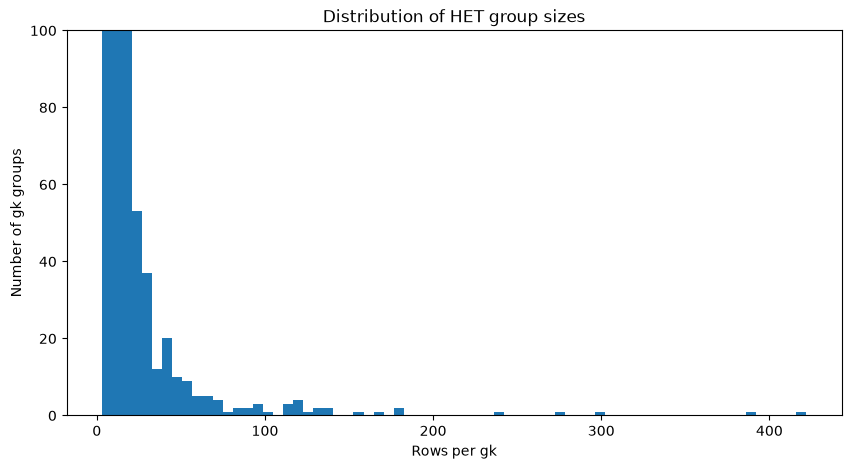

In [332]:
import matplotlib.pyplot as plt

group_sizes = HET.groupby("gk").size()

plt.figure(figsize=(10, 5))
plt.hist(group_sizes, bins=70)
plt.ylim(0, 100)
plt.xlabel("Rows per gk")
plt.ylabel("Number of gk groups")
plt.title("Distribution of HET group sizes")
plt.show()

In [ ]:
def show_similar(line_id, n=10):
    row = homo_tovar.loc[homo_tovar["line_id"] == line_id].iloc[0]
    G = homo_tovar[homo_tovar["gk"] == row["gk"]]
    texts, tid = np.unique(G["desc"].to_numpy(dtype=str), return_inverse=True)
    X = _tfidf(texts) 
    s = (X[np.searchsorted(texts, row["desc"])] @ X.T).toarray().ravel()[tid]
    out = G.assign(sim=s.round(2))
    out = out[out["customer_bin"] != row["customer_bin"]]
    print(f"{row['plan_extra_desc']}  |  {row['unit_price_st']:,.0f}")
    return out.sort_values("sim", ascending=False).head(n)[
        ["sim", "unit_price_st", "customer_bin", "plan_extra_desc"]]

In [266]:
show_similar(53195022)

KeyError: 'desc'

In [ ]:
HET_RES[HET_RES['desc_status']=='ok'] 

,line_id,contract_id,lot_id,plan_id,customer_bin,supplier_bin,year,sign_date,status,fact_trade_method,...,sim_ref_customers,sim_fair_median,sim_fair_mean,code_ref_n,code_fair_median,sim_enough,sim_dev_median,sim_dev_mean,code_dev_median,desc_status
222,46864091,20264189,30961130,70016609.0,231040023028,020923501342,2024,2024-05-15 10:48:56,Исполнен,Запрос ценовых предложений,...,3,4439.252016,5.512980e+03,8,4245.795293,True,0.970922,0.587058,1.060725,ok
226,49655775,21650618,32110601,71162636.0,990340005977,820704400450,2024,2024-12-29 13:31:58,Расторгнут по соглашению сторон,Запрос ценовых предложений,...,3,5941.118414,5.523842e+03,9,4439.252016,True,0.782918,0.917602,1.386107,ok
227,45116307,19414420,28886088,64318742.0,231040023028,810806301138,2024,2024-01-26 18:16:12,Расторгнут в одностороннем порядке,Запрос ценовых предложений,...,3,4439.252016,5.512980e+03,8,4245.795293,True,0.676630,0.350084,0.753025,ok
272,49704714,21670033,28603675,63519874.0,971040001050,920309401145,2024,2024-12-30 12:05:12,Исполнен,Запрос ценовых предложений,...,2,875.900256,1.355300e+03,6,1330.273513,True,-0.619925,-0.754366,-0.749745,ok
277,53829823,23730579,38579556,80855418.0,171041003124,850702303097,2025,2025-11-07 09:37:11,Исполнен,Запрос ценовых предложений,...,3,847.402268,3.047222e+03,9,3806.110951,True,2.460814,-0.037582,-0.229475,ok
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16643,57066687,25279825,41455196,86227408.0,940940000384,210440008151,2026,2026-05-26 11:28:07,Действует,Открытый конкурс,...,2,325370.250123,1.148952e+06,17,310888.809067,True,0.129600,-0.680110,0.182217,ok
16644,57065651,25279241,41456550,86227336.0,940940000384,220440001394,2026,2026-05-26 11:06:48,Действует,Открытый конкурс,...,2,325370.250123,1.148952e+06,17,310888.809067,True,1.503523,-0.291031,1.620139,ok
16645,58248564,25901059,43090429,87787388.0,000740001307,171140020431,2026,2026-10-06 14:04:17,Действует,Открытый конкурс,...,2,325370.250123,3.482745e+05,15,187825.857577,True,3.381163,3.093036,6.589477,ok
16646,58248563,25901059,43090431,87787385.0,000740001307,171140020431,2026,2026-10-06 14:04:17,Действует,Открытый конкурс,...,2,325370.250123,3.482745e+05,15,187825.857577,True,10.556066,9.796083,19.018543,ok


In [279]:
HET_RES[HET_RES['gk']=='262040.000.000282|796'].columns#[['unit_price','plan_name','plan_desc','plan_extra_desc','tokens']]

Index(['line_id', 'contract_id', 'lot_id', 'plan_id', 'customer_bin', 'supplier_bin', 'year', 'sign_date', 'status', 'fact_trade_method', 'is_single_source', 'enstru_code', 'unit_code',
       'item_name_ru', 'quantity', 'unit_price', 'total_sum', 'region_code', 'region_source', 'subject_type', 'plan_name', 'plan_desc', 'plan_extra_desc', 'lot_name', 'lot_desc', 'month', 'gk',
       'К предыдущему месяцу товары и услуги - 2026-10', 'unit_price_st', 'log_p', 'grp_n', 'grp_med', 'data_issue', 'n_clean', 'n_all', 'med_clean', 'mad', 'mad_factor', 'far_share', 'tier',
       'het_reason', 'is_extreme', 'ratio', 'desc', 'text_id', 'nn_sim', 'sim_ref_n', 'sim_ref_customers', 'sim_fair_median', 'sim_fair_mean', 'code_ref_n', 'code_fair_median', 'sim_enough',
       'sim_dev_median', 'sim_dev_mean', 'code_dev_median', 'desc_status', 'tokens', 'mdl_ref_n', 'mdl_ref_customers', 'mdl_fair_median', 'mdl_fair_mean'],
      dtype='str')

In [272]:
# 1) Басқа ұйымның ең ұқсас сипаттамасымен ұқсастықтың таралуы
print(HET_RES["nn_sim"].quantile([.1, .25, .5, .75, .9]).round(2), "\n")

# 2) Сипаттаманың ұзындығы (таңба)
print(HET_RES["desc"].str.len().quantile([.1, .5, .9]), "\n")

# 3) Әр топта неше ұйым бар (эталонға 2 басқа ұйым керек, яғни топта кемінде 3)
n_cust = HET.groupby("gk")["customer_bin"].nunique()
print(n_cust.quantile([.25, .5, .75, .9]))
print("3+ ұйымы бар топтардағы жолдар үлесі:",
      round((HET["gk"].map(n_cust) >= 3).mean(), 3), "\n")

# 4) Ең үлкен топтан әр ұйымның бір сипаттамасы
gk_big = HET["gk"].value_counts().index[0]
sample = HET[HET["gk"] == gk_big].drop_duplicates("customer_bin").head(8)
print(gk_big, "|", sample["item_name_ru"].iloc[0])
for _, r in sample.iterrows():
    print(f"{r['unit_price_st']:>12,.0f} | {str(r['plan_extra_desc'])[:250]}")

0.10    0.00
0.25    0.06
0.50    0.18
0.75    0.35
0.90    0.54
Name: nn_sim, dtype: float64 

0.1     25.0
0.5     75.0
0.9    287.0
Name: desc, dtype: float64 

0.25    2.0
0.50    2.0
0.75    4.0
0.90    6.0
Name: customer_bin, dtype: float64
3+ ұйымы бар топтардағы жолдар үлесі: 0.577 

262040.000.000282|796 | Картридж
     176,288 | Картридж для лазерного принтера HP Color LaserJet CP5225, пурпурный, ресурс 7300 страниц
     178,958 | Картридж HP COLOR LJ Enterprise M855xh (картриджи)(черный)
      16,019 | Картридж для цветного принтера Canon/i-SENSYS LBP631Cw, вид лазерный, цвет печати желтый
       9,233 | Картридж для МФУ DocuCentre SC2020 
(черный цвет)
     235,920 | Картридж для принтера CP5525DN, CE2753A - пурпурный, Размеры упаковки 490 x 190 x 220 мм. Вес 2,8 кг. Оригинальный картридж с чипом. Упаковка из  плотного твердого картона. Год выпуска 2024-2025 г.
     141,204 | Тонер, цвет желтый, для XEROX Vercant 3100 Press (оригинал) ресурс 55 000 копий при 5% заполнении ф

In [273]:
LOOK = str.maketrans("авекмнорстух", "abekmhopctyx")   # латынға ұқсас кирилл әріптері

def model_tokens(s):
    s = str(s).lower().replace("ё", "е")
    s = re.sub(r"(?<=[a-zа-я])-(?=\d)", "", s)          # TK-1170 → tk1170
    out = set()
    for t in re.split(r"[^\w]+", s):
        if not re.search(r"\d", t):
            continue
        t = t.translate(LOOK)                            # кириллмен терілген «СЕ273А» → ce273a
        if (len(t) >= 4 and re.fullmatch(r"[a-z0-9]+", t) and re.search(r"[a-z]", t)
                and not re.fullmatch(r"\d+[a-z]{1,3}", t)      # 220mm, 500ml сияқты өлшемдер
                and not re.fullmatch(r"\d+(x\d+)+", t)):       # 490x190x220
            out.add(t)
    return sorted(out)

HET_RES["tokens"] = HET_RES["plan_extra_desc"].map(model_tokens)

# Бір gk ішінде ортақ модель коды бар, басқа ұйымдардың таза жолдары
tok = (HET_RES[["line_id", "gk", "customer_bin", "unit_price_st", "data_issue", "tokens"]]
       .explode("tokens").dropna(subset=["tokens"]))
ref = tok[tok["data_issue"].isna() & (tok["unit_price_st"] > 0)]
pairs = tok[["line_id", "gk", "customer_bin", "tokens"]].merge(
    ref[["line_id", "gk", "customer_bin", "tokens", "unit_price_st"]],
    on=["gk", "tokens"], suffixes=("", "_ref"))
pairs = (pairs[pairs["customer_bin"] != pairs["customer_bin_ref"]]
         .drop_duplicates(["line_id", "line_id_ref"]))

mdl = pairs.groupby("line_id").agg(
    mdl_ref_n=("line_id_ref", "size"),
    mdl_ref_customers=("customer_bin_ref", "nunique"),
    mdl_fair_median=("unit_price_st", "median"),
    mdl_fair_mean=("unit_price_st", "mean"),
)
mdl_cols = ["mdl_ref_n", "mdl_ref_customers", "mdl_fair_median", "mdl_fair_mean"]
HET_RES = HET_RES.drop(columns=mdl_cols, errors="ignore").merge(
    mdl, left_on="line_id", right_index=True, how="left")
HET_RES[["mdl_ref_n", "mdl_ref_customers"]] = HET_RES[["mdl_ref_n", "mdl_ref_customers"]].fillna(0).astype(int)

In [274]:
print("Модель коды бар жолдар:", round((HET_RES["tokens"].str.len() > 0).mean(), 3), "\n")

for n_min, c_min in [(5, 2), (3, 2), (2, 1)]:
    v = HET_RES[(HET_RES["mdl_ref_n"] >= n_min) & (HET_RES["mdl_ref_customers"] >= c_min)
                & (HET_RES["unit_price_st"] > 0)]
    d_code = np.exp(np.log(v["unit_price_st"] / v["code_fair_median"]).abs().median())
    d_mdl  = np.exp(np.log(v["unit_price_st"] / v["mdl_fair_median"]).abs().median())
    print(f"n≥{n_min}, ұйым≥{c_min}: {len(v):>5} жол | код {d_code:.2f} есе | модель {d_mdl:.2f} есе")

print("\nЕң жиі модель кодтары:")
print(tok["tokens"].value_counts().head(20))


Модель коды бар жолдар: 0.175 

n≥5, ұйым≥2:    64 жол | код 2.36 есе | модель 2.08 есе
n≥3, ұйым≥2:    91 жол | код 2.76 есе | модель 2.05 есе
n≥2, ұйым≥1:   217 жол | код 3.01 есе | модель 2.30 есе

Ең жиі модель кодтары:
tokens
au680                96
4matic               57
ip65                 51
au480                48
ip20                 48
cfx96                47
s560                 35
s560l                26
s580                 26
e200                 25
m855xh               24
w221                 22
m454dn               22
s500l                21
b9100                21
ip44                 21
m570dn               20
ip54                 20
cn3000               19
kmhl341bbma116664    19
Name: count, dtype: int64


In [334]:
HET['gk'].nunique(),homo_tovar['gk'].nunique()

(981, 3839)

In [494]:
df['enstru_code'].nunique()

8718

In [513]:
services = df[
    (df["status"] != "Не заключен")
    & df["sign_date"].notna()
    & df["unit_code"].notna()
    & (df["quantity"] > 0)
    & df["subject_type"].isin(["3"])          # тауар, қызмет
].copy() 
services["gk"] = services["enstru_code"] + "|" + services["unit_code"]
services['gk'].nunique()

400

In [400]:
inflations.columns

Index(['month', 'К предыдущему месяцу товары и услуги', 'К предыдущему месяцу товары и услуги - 2026-10', 'К предыдущему месяцу товары продоволь-ственные',
       'К предыдущему месяцу товары продоволь-ственные - 2026-10', 'К предыдущему месяцу товары непродо-вольственные', 'К предыдущему месяцу товары непродо-вольственные - 2026-10',
       'К предыдущему месяцу платные услуги', 'К предыдущему месяцу платные услуги - 2026-10'],
      dtype='str')

In [515]:
services["month"] = pd.to_datetime(services["sign_date"]).dt.to_period("M").dt.to_timestamp()

services = services.merge(
    inflations[["month", "К предыдущему месяцу платные услуги - 2026-10"]],
    on="month",
    how="left",
)
services['unit_price_st'] = services['unit_price']*services['К предыдущему месяцу платные услуги - 2026-10']
services.head(2)

,line_id,contract_id,lot_id,plan_id,customer_bin,supplier_bin,year,sign_date,plan_exec_date,fact_exec_date,...,subject_type,plan_name,plan_desc,plan_extra_desc,lot_name,lot_desc,month,gk,К предыдущему месяцу платные услуги - 2026-10,unit_price_st
0,53333031,23479593,38066972,80146762.0,051040005150,200340012471,2025,2025-09-22 10:11:28,2025-12-31 10:35:54,2025-12-03 16:25:08,...,3,Услуги по организации/проведению конференций/семинаров/форумов/конкурсов/корпоративных/спортивных/культурных/праздни...,Услуги по организации/проведению конференций/семинаров/форумов/конкурсов/корпоративных/спортивных/культурных/праздни...,Концертная программа ко Дню Республики Казахстан,Услуги по организации/проведению конференций/семинаров/форумов/конкурсов/корпоративных/спортивных/культурных/праздни...,Услуги по организации/проведению конференций/семинаров/форумов/конкурсов/корпоративных/спортивных/культурных/праздни...,2025-09-01,823011.000.000000|5114,1.10237,9.833139e+05
1,53098371,23360149,0,80099733.0,210240033968,200140023023,2025,2025-09-03 11:36:45,2025-12-31 10:58:47,2025-09-26 11:29:29,...,3,Услуги по предоставлению доступа к информационным ресурсам,"Услуги по предоставлению доступа к информационным ресурсам (сертификация пользователей, получение доступа и др.)",Подписка на предоставление доступа к сервису по проверке контрагентов (юр.лиц),NaN,NaN,2025-09-01,620920.000.000013|5114,1.10237,1.653555e+06


In [516]:
MIN_N = 3                     # шашыраңқылықты өлшеуге ең аз жол саны
MAD_LIMIT = np.log(5) / 2     # әдеттегі ауытқу ≈ 2.24 есе
FAR_LIMIT = 0.20              # медианадан 3 есе алшақ жолдардың үлесі
FAR_MIN_N = 5                 # үлесті есептеуге ең аз жол саны

print("unit_price_st бос немесе ≤ 0:",
      (services["unit_price_st"].isna() | (services["unit_price_st"] <= 0)).sum())

# 0) Инфляцияға түзетілген бағаның логарифмі
services["log_p"] = np.log(services["unit_price_st"].where(services["unit_price_st"] > 0))

# 1) Топ медианасы және медианадан 10 есе алшақ жолдар
grp = services.groupby("gk")["log_p"]
services["grp_n"] = grp.transform("count")
services["grp_med"] = grp.transform("median")
dev = services["log_p"] - services["grp_med"]

services["data_issue"] = None
services.loc[(services["grp_n"] >= MIN_N) & (dev >=  np.log(10)), "data_issue"] = "extreme_high"
services.loc[(services["grp_n"] >= MIN_N) & (dev <= -np.log(10)), "data_issue"] = "extreme_low"

# 2) Таза жолдар: медиана және MAD
clean = services[services["data_issue"].isna()]
med_clean = clean.groupby("gk")["log_p"].median()
abs_dev_clean = (clean["log_p"] - clean["gk"].map(med_clean)).abs()

stats = abs_dev_clean.groupby(clean["gk"]).agg(n_clean="count", mad="median")
stats["med_clean"] = med_clean
stats["mad_factor"] = np.exp(stats["mad"])

# 3) Алшақ жолдардың үлесі: БАРЛЫҚ жолдардан (шеткілерін қоса), таза медианаға қатысты
all_dev = (services["log_p"] - services["gk"].map(med_clean)).abs()
far_flag = (all_dev > np.log(3)).where(all_dev.notna())
far = far_flag.groupby(services["gk"]).agg(n_all="count", far_share="mean")
stats = stats.join(far)

# 4) Екі топ: біртекті / әртекті (+ өлшеуге дерегі аз)
by_mad = stats["mad"] > MAD_LIMIT
by_far = (stats["n_all"] >= FAR_MIN_N) & (stats["far_share"] > FAR_LIMIT)

stats["tier"] = np.select(
    [stats["n_all"] < MIN_N,                                   # жалпы жол аз
     by_mad | by_far | (stats["n_clean"] < MIN_N)],            # шашыраңқы, алшақтар көп немесе таза жол аз қалды
    ["small", "heterogeneous"],
    default="homogeneous",
)
stats["het_reason"] = np.select(
    [stats["tier"] != "heterogeneous", stats["n_clean"] < MIN_N, by_mad & by_far, by_mad],
    ["", "extremes", "mad+far", "mad"],
    default="far",
)

# 5) Әр жолға тобының нәтижесін қосу
cols = ["n_clean", "n_all", "med_clean", "mad", "mad_factor", "far_share", "tier", "het_reason"]
services = services.drop(columns=cols, errors="ignore").merge(
    stats[cols], left_on="gk", right_index=True, how="left")
services["tier"] = services["tier"].fillna("small")

print(services["data_issue"].value_counts())

unit_price_st бос немесе ≤ 0: 0
data_issue
extreme_high    447
extreme_low     406
Name: count, dtype: int64


In [403]:
services[['plan_name','plan_desc','plan_extra_desc']]

,plan_name,plan_desc,plan_extra_desc
0,Услуги по вывозу (сбору) опасных отходов/имущества/материалов,Услуги по вывозу (сбору) опасных отходов/имущества/материалов,"Утилизация энергосберегающих, люминесцентных, ртутосодержащих ламп.Утилизация медицинских отходов"
1,Услуги по техническому обслуживанию автоматизированных систем управления/контроля/мониторинга/учета/диспетчеризации ...,Услуги по техническому обслуживанию автоматизированных систем управления/контроля/мониторинга/учета/диспетчеризации ...,Обслуживание приборов учета тепловой энергии
2,Услуги по предоставлению доступа к информационным ресурсам,"Услуги по предоставлению доступа к информационным ресурсам (сертификация пользователей, получение доступа и др.)",Подписка на предоставление доступа к сервису по проверке контрагентов (юр.лиц)
3,Услуги по установке/настройке программного обеспечения,Услуги по установке/настройке программного обеспечения,"Право на пользование ПО (антивирус), согласно техспец"
4,Услуги по осуществлению авторского надзора,Услуги по осуществлению авторского надзора,Авторский надзор по реконструкции теплового пункта для подключения СЛК- 200 коек к центральному отоплению
...,...,...,...
6863,Услуги по предоставлению информации,"Услуги по предоставлению информации (информации из СМИ, из баз данных, других собранных/обработанных сведений)",Доступ к интернет-ресурсу Учёт.kz
6864,Услуги по ускоренной/курьерской почтовой связи,Услуги по ускоренной/курьерской почтовой связи,Услуги по ускоренной курьерской почтовой связи по Республике Казахстан (37 отправлений)
6865,Услуги по организации/проведению конференций/семинаров/форумов/конкурсов/корпоративных/спортивных/культурных/праздни...,Услуги по организации/проведению конференций/семинаров/форумов/конкурсов/корпоративных/спортивных/культурных/праздни...,Концертная программа ко Дню Республики Казахстан
6866,Услуги по огнезащитному предохранению древесины,Услуги по предохранению древесины путем обработки огнезащитным составом,Огнезащитная и антисептическая обработка деревянных перекрытий кровли зданий


In [475]:
COLOR_RE = re.compile(
    r"^(черн|бел|желт|пурпурн|голуб|син|красн|зелен|сер|коричнев|оранжев|фиолетов|розов|бежев)"
    r"(ый|ий|ой|ая|яя|ое|ее|ые|ие|ого|его|ому|ему|ым|им|ую|юю|ых|их)$"
)
CYR_STOP = {"для", "цвет", "цвета", "цвете"}

def cyr_text(s):
    s = str(s).lower().replace("ё", "е")
    words = re.findall(r"[а-яәғқңөұүһі]{3,}", s)        # тек кирилл сөздер, 3 әріптен
    return " ".join(w for w in words if w not in CYR_STOP and not COLOR_RE.match(w))

services["desc_cyr"] = services["plan_extra_desc"].fillna("").map(cyr_text)
services[["plan_extra_desc", "desc_cyr"]].sample(5)

,plan_extra_desc,desc_cyr
4739,"Услуги телекоммуникаций: услуги связи, междугородняя и международная связь.",услуги телекоммуникаций услуги связи междугородняя международная связь
247,"Обучение семинару ""Комплаенс - офицер по ISO 37301:2021""",обучение семинару комплаенс офицер
2713,"Услуги по вывозу твердо-бытовых отходов. Объем ТБО- 343,2 м3",услуги вывозу твердо бытовых отходов объем тбо
4121,Услуги по страхованию автомобильного транспорта,услуги страхованию автомобильного транспорта
3487,Услуга аренды канала в кабельной канализации,услуга аренды канала кабельной канализации


In [476]:
import re
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer

SIM = 0.5      # сипаттамалардың ұқсастық шегі (0–1)
MIN_N = 3        # эталонда кемінде 5 жол
MIN_CUST = 2     # және кемінде 2 басқа ұйым

def norm_text(s):
    s = str(s).lower().replace("ё", "е")
    s = re.sub(r"[^\w]+", " ", s)            # тыныс белгілері кетеді, сандар қалады
    return re.sub(r"\s+", " ", s).strip()

def _tfidf(texts):
    try:
        return TfidfVectorizer(analyzer="char_wb", ngram_range=(7, 13),
                               sublinear_tf=True).fit_transform(texts)
    except ValueError:                       # топтағы барлық сипаттама бос болса
        return sparse.csr_matrix((len(texts), 1))


services["desc"] = services["desc_cyr"].fillna("").map(norm_text) 
services[["plan_extra_desc","desc"]].head(5)

,plan_extra_desc,desc
0,Концертная программа ко Дню Республики Казахстан,концертная программа дню республики казахстан
1,Подписка на предоставление доступа к сервису по проверке контрагентов (юр.лиц),подписка предоставление доступа сервису проверке контрагентов лиц
2,"Право на пользование ПО (антивирус), согласно техспец",право пользование антивирус согласно техспец
3,Авторский надзор по реконструкции теплового пункта для подключения СЛК- 200 коек к центральному отоплению,авторский надзор реконструкции теплового пункта подключения слк коек центральному отоплению
4,Технический надзор по реконструкции теплового пункта для подключения СЛК- 200 коек к центральному отоплению,технический надзор реконструкции теплового пункта подключения слк коек центральному отоплению


In [477]:
import pymorphy3
from functools import lru_cache
from collections import Counter

morph = pymorphy3.MorphAnalyzer()

STOP = {"для", "или", "что", "как", "так", "также", "при", "под", "над", "без", "весь",
        "свой", "который", "этот", "согласно", "оказание", "услуга", "выполнение"}

@lru_cache(maxsize=None)                    # әр сөз тек бір рет талданады
def lemma(w):
    return morph.parse(w)[0].normal_form.replace("ё", "е")

def lemmatize(s):
    return " ".join(l for l in (lemma(w) for w in s.split()) if l not in STOP)

uniq = services["desc"].unique()
lem_map = {t: lemmatize(t) for t in tqdm(uniq, desc="лемматизация")}
services["desc_lem"] = services["desc"].map(lem_map)

лемматизация: 100%|██████████| 3827/3827 [00:01<00:00, 2459.17it/s]


In [478]:
def similar_fair_price_gk(g, sim=SIM, col="desc"):
    """Бір gk ішіндегі әр жол үшін: сипаттамасы ұқсас эталон және бүкіл код эталоны,
    екеуі де тек басқа ұйымдардың таза жолдарынан."""
    g = g.reset_index(drop=True)
    texts, tid = np.unique(g[col].to_numpy(dtype=str), return_inverse=True)
    X = _tfidf(texts)

    price = g["unit_price_st"].to_numpy(dtype=float) 
    cust = g["customer_bin"].to_numpy() 
    ok = ((g["unit_price_st"] > 0)).to_numpy()   # эталонға жарамды 

    rows = []
    for i in range(len(texts)):
        s = (X[i] @ X.T).toarray().ravel()[tid]      # i-сипаттаманың әр жолмен ұқсастығы
        near = s >= sim
        for c in np.unique(cust[tid == i]):
            other = ok & (cust != c)                  # өз ұйымының жолдары кірмейді
            p_sim, p_code = price[other & near], price[other]
            rows.append({
                "text_id": i, "customer_bin": c,
                "nn_sim": s[other].max() if other.any() else 0.0,
                "sim_ref_n": p_sim.size,
                "sim_ref_customers": pd.unique(cust[other & near]).size,
                "sim_fair_median": np.median(p_sim) if p_sim.size else np.nan,
                "sim_fair_mean": p_sim.mean() if p_sim.size else np.nan,
                "code_ref_n": p_code.size,
                "code_fair_median": np.median(p_code) if p_code.size else np.nan,
            })
    return g.assign(text_id=tid).merge(pd.DataFrame(rows),
                                       on=["text_id", "customer_bin"], how="left")

In [411]:
from tqdm.auto import tqdm

# parts = [similar_fair_price_gk(g) for _, g in tqdm(services.groupby("gk"), total=services["gk"].nunique())] # for without lemmatization
parts = [similar_fair_price_gk(g, col="desc_lem")
         for _, g in tqdm(services.groupby("gk"), total=services["gk"].nunique())]
serv_res = pd.concat(parts, ignore_index=True) 

serv_res["sim_enough"] = (serv_res["sim_ref_n"] >= MIN_N) & (serv_res["sim_ref_customers"] >= MIN_CUST)
serv_res["sim_dev_median"] = serv_res["unit_price_st"] / serv_res["sim_fair_median"] - 1
serv_res["sim_dev_mean"] = serv_res["unit_price_st"] / serv_res["sim_fair_mean"] - 1
serv_res["code_dev_median"] = serv_res["unit_price_st"] / serv_res["code_fair_median"] - 1
# serv_res["desc_status"] = np.select(
#     [serv_res["desc"] == "", serv_res["nn_sim"] < SIM, ~serv_res["sim_enough"]],
#     ["no_desc", "unique_desc", "few_similar"],
#     default="ok",
# ) 
serv_res["desc_status"] = np.select(
    [serv_res["desc_lem"] == "", serv_res["nn_sim"] < SIM, ~serv_res["sim_enough"]],
    ["no_desc", "unique_desc", "few_similar"],
    default="ok",
)

100%|██████████| 400/400 [00:10<00:00, 37.68it/s] 


In [394]:
from itertools import product
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

NGRAMS    = [(4,6),(4,7),(4,8),(4,9),(4,10),(4,11),(5,6),(5,7),(5,8),(5,9),(5,10),(5,11)]
SIMS      = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
MIN_NS    = [2, 3, 4, 5, 6, 7, 8]
MIN_CUSTS = [1, 2, 3, ]

def _tfidf(texts, ngram=(3, 5)):
    try:
        return TfidfVectorizer(analyzer="char_wb", ngram_range=ngram,
                               sublinear_tf=True).fit_transform(texts)
    except ValueError:
        return sparse.csr_matrix((len(texts), 1))

def sweep_gk(g, ngram, sims, col="desc"):
    """Бір gk: ұқсастық бір рет есептеледі, эталон әр SIM үшін бөлек жиналады."""
    g = g.reset_index(drop=True)
    texts, tid = np.unique(g[col].to_numpy(dtype=str), return_inverse=True)
    X = _tfidf(texts, ngram)
    price = g["unit_price_st"].to_numpy(dtype=float)
    cust = g["customer_bin"].to_numpy()
    ok = price > 0

    rows = []
    for i in range(len(texts)):
        s = (X[i] @ X.T).toarray().ravel()[tid]
        for c in np.unique(cust[tid == i]):
            other = ok & (cust != c)
            p_code = price[other]
            base = {"text_id": i, "customer_bin": c,
                    "nn_sim": s[other].max() if other.any() else 0.0,
                    "code_fair_median": np.median(p_code) if p_code.size else np.nan}
            for t in sims:
                m = other & (s >= t)
                p = price[m]
                rows.append({**base, "sim": t, "sim_ref_n": p.size,
                             "sim_ref_customers": pd.unique(cust[m]).size,
                             "sim_fair_median": np.median(p) if p.size else np.nan})

    lines = g.assign(text_id=tid, empty=(g[col] == ""))[
        ["line_id", "text_id", "customer_bin", "unit_price_st", "empty"]]
    return lines.merge(pd.DataFrame(rows), on=["text_id", "customer_bin"])

CACHE = {}   # (ngram, SIM) → әр жолдың эталоны

def ensure(ngram, sims, df=None):
    """Кэште жоқ SIM мәндерін ғана есептейді."""
    df = services if df is None else df
    missing = [t for t in sims if (ngram, t) not in CACHE]
    if not missing:
        return
    parts = [sweep_gk(g, ngram, missing)
             for _, g in tqdm(df.groupby("gk"), total=df["gk"].nunique(), desc=f"ngram {ngram}")]
    res = pd.concat(parts, ignore_index=True)
    for t, r in res.groupby("sim"):
        CACHE[(ngram, t)] = r.drop(columns="sim").reset_index(drop=True)

def build_summary(ngrams, sims, min_ns, min_custs):
    rows = []
    for ngram in ngrams:
        ensure(ngram, sims)
        for t in sims:
            r = CACHE[(ngram, t)]
            price = r["unit_price_st"].to_numpy(dtype=float)
            n, cu = r["sim_ref_n"].to_numpy(), r["sim_ref_customers"].to_numpy()
            with np.errstate(divide="ignore", invalid="ignore"):
                d_code = np.abs(np.log(price / r["code_fair_median"].to_numpy(dtype=float)))
                d_sim  = np.abs(np.log(price / r["sim_fair_median"].to_numpy(dtype=float)))
            empty = r["empty"].to_numpy(dtype=bool)
            unique = ~empty & (r["nn_sim"].to_numpy() < t)
            for min_n, min_cust in product(min_ns, min_custs):
                enough = (n >= min_n) & (cu >= min_cust)
                v = enough & (price > 0)
                rows.append({
                    "ngram": f"{ngram[0]}-{ngram[1]}", "SIM": t, "MIN_N": min_n, "MIN_CUST": min_cust,
                    "lines": int(v.sum()),
                    "dev_code": np.exp(np.nanmedian(d_code[v])) if v.any() else np.nan,
                    "dev_sim_median":  np.exp(np.nanmedian(d_sim[v]))  if v.any() else np.nan,
                    "dev_sim_mean":  np.exp(np.nanmean(d_sim[v]))  if v.any() else np.nan,
                    "ok":          (~empty & ~unique & enough).mean(),
                    "few_similar": (~empty & ~unique & ~enough).mean(),
                    "unique_desc": unique.mean(),
                    "no_desc":     empty.mean(),
                })
    out = pd.DataFrame(rows)
    out["ngram"] = pd.Categorical(out["ngram"], ordered=True,
                                  categories=[f"{a}-{b}" for a, b in ngrams])
    return out

summary = build_summary(NGRAMS, SIMS, MIN_NS, MIN_CUSTS)
print(len(summary), "комбинация")

ngram (5, 11): 100%|██████████| 400/400 [00:10<00:00, 38.82it/s]


2268 комбинация


In [413]:
from itertools import product
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

LEM_NGRAMS = [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), ]
SIMS       = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
MIN_NS     = [2, 3, 4, 5, 6, 7, 8]
MIN_CUSTS  = [1, 2, 3, 4, 5]

def _tfidf_word(texts, ngram=(1, 1)):
    try:
        return TfidfVectorizer(analyzer="word", ngram_range=ngram,
                               sublinear_tf=True).fit_transform(texts)
    except ValueError:
        return sparse.csr_matrix((len(texts), 1))

def sweep_gk_lem(g, ngram, sims, col="desc_lem"):
    """Бір gk: ұқсастық бір рет есептеледі, эталон әр SIM үшін бөлек жиналады."""
    g = g.reset_index(drop=True)
    texts, tid = np.unique(g[col].to_numpy(dtype=str), return_inverse=True)
    X = _tfidf_word(texts, ngram)
    price = g["unit_price_st"].to_numpy(dtype=float)
    cust = g["customer_bin"].to_numpy()
    ok = price > 0

    rows = []
    for i in range(len(texts)):
        s = (X[i] @ X.T).toarray().ravel()[tid]
        for c in np.unique(cust[tid == i]):
            other = ok & (cust != c)
            p_code = price[other]
            base = {"text_id": i, "customer_bin": c,
                    "nn_sim": s[other].max() if other.any() else 0.0,
                    "code_fair_median": np.median(p_code) if p_code.size else np.nan}
            for t in sims:
                m = other & (s >= t)
                p = price[m]
                rows.append({**base, "sim": t, "sim_ref_n": p.size,
                             "sim_ref_customers": pd.unique(cust[m]).size,
                             "sim_fair_median": np.median(p) if p.size else np.nan})

    lines = g.assign(text_id=tid, empty=(g[col] == ""))[
        ["line_id", "text_id", "customer_bin", "unit_price_st", "empty"]]
    return lines.merge(pd.DataFrame(rows), on=["text_id", "customer_bin"])

CACHE_LEM = {}   # (ngram, SIM) → әр жолдың эталоны

def ensure_lem(ngram, sims):
    missing = [t for t in sims if (ngram, t) not in CACHE_LEM]
    if not missing:
        return
    parts = [sweep_gk_lem(g, ngram, missing)
             for _, g in tqdm(services.groupby("gk"), total=services["gk"].nunique(),
                              desc=f"сөз {ngram}")]
    res = pd.concat(parts, ignore_index=True)
    for t, r in res.groupby("sim"):
        CACHE_LEM[(ngram, t)] = r.drop(columns="sim").reset_index(drop=True)

def build_summary_lem(ngrams, sims, min_ns, min_custs):
    lbl = lambda ng: f"w{ng[0]}-{ng[1]}"          # «w» — сөз деңгейі, әріп тіркестерінен ажырату үшін
    rows = []
    for ngram in ngrams:
        ensure_lem(ngram, sims)
        for t in sims:
            r = CACHE_LEM[(ngram, t)]
            price = r["unit_price_st"].to_numpy(dtype=float)
            n, cu = r["sim_ref_n"].to_numpy(), r["sim_ref_customers"].to_numpy()
            with np.errstate(divide="ignore", invalid="ignore"):
                d_code = np.abs(np.log(price / r["code_fair_median"].to_numpy(dtype=float)))
                d_sim  = np.abs(np.log(price / r["sim_fair_median"].to_numpy(dtype=float)))
            empty = r["empty"].to_numpy(dtype=bool)
            unique = ~empty & (r["nn_sim"].to_numpy() < t)
            for min_n, min_cust in product(min_ns, min_custs):
                enough = (n >= min_n) & (cu >= min_cust)
                v = enough & (price > 0)
                rows.append({
                    "ngram": lbl(ngram), "SIM": t, "MIN_N": min_n, "MIN_CUST": min_cust,
                    "lines": int(v.sum()),
                    "dev_code": np.exp(np.nanmedian(d_code[v])) if v.any() else np.nan,
                    "dev_sim":  np.exp(np.nanmedian(d_sim[v]))  if v.any() else np.nan,
                    "ok":          (~empty & ~unique & enough).mean(),
                    "few_similar": (~empty & ~unique & ~enough).mean(),
                    "unique_desc": unique.mean(),
                    "no_desc":     empty.mean(),
                })
    out = pd.DataFrame(rows)
    out["ngram"] = pd.Categorical(out["ngram"], ordered=True, categories=[lbl(ng) for ng in ngrams])
    return out

summary_lem = build_summary_lem(LEM_NGRAMS, SIMS, MIN_NS, MIN_CUSTS)
print(len(summary_lem), "комбинация")

сөз (1, 5): 100%|██████████| 400/400 [00:08<00:00, 46.80it/s]


1575 комбинация


In [417]:
def nearest_other(line_id, col="desc_lem", n=3):
    row = services.loc[services["line_id"] == line_id].iloc[0]
    G = services[services["gk"] == row["gk"]]
    texts, tid = np.unique(G[col].to_numpy(dtype=str), return_inverse=True)
    X = _tfidf_word(texts, (1, 1))
    s = (X[np.searchsorted(texts, row[col])] @ X.T).toarray().ravel()[tid]
    out = G.assign(sim=s.round(2))
    out = out[out["customer_bin"] != row["customer_bin"]]
    return row, out.sort_values("sim", ascending=False).head(n)

cand = services[services["gk"].map(n_cust) >= 3].sample(8, random_state=1)
for lid in cand["line_id"]:
    row, nb = nearest_other(lid)
    print(f"■ {row['unit_price_st']:>12,.0f} | {str(row['plan_extra_desc'])[:150]}")
    for _, r in nb.iterrows():
        print(f"  {r['sim']:.2f} {r['unit_price_st']:>12,.0f} | {str(r['plan_extra_desc'])[:150]}")
    print()

■       75,667 | Установлению границ земельного участка на местности площадью 2,5663 га (более 1,0га), расположенный по адресу г. Астана р-н Есиль ул Е495 зд.6
  0.39       87,528 | Услуги по изготовлению акта установления границ на земельные участки, расположенные по адресу: город Астана, проспект Женис 11
  0.20      161,501 | Услуги по регистрации земельных участков
  0.20       71,441 | Услуги по регистрации земельных участков

■    5,392,953 | Интернет канал основной 150/150 Мб/сек (оптическая выделенная пара)
  0.51    9,563,075 | Услуга доступа к сети Интернет (основной канал)
  0.51   23,187,936 | Услуга доступа к сети Интернет (основной канал)
  0.47   31,805,432 | Услуга доступа к сети Интернет 800 Мбит/с, основной канал

■    2,899,708 | Обязательное страхование гражданско-правовой ответственности владельцев транспортных средств
  1.00      113,817 | Услуги обязательного страхования гражданско-правовой ответственности владельцев транспортных средств
  1.00       73,384 | Усл

In [426]:
summary_lem['dev_sim'].describe(), summary_lem['dev_code'].describe()

(count    1575.000000
 mean        2.900784
 std         0.233635
 min         2.213045
 25%         2.768037
 50%         2.902240
 75%         3.053430
 max         3.468556
 Name: dev_sim, dtype: float64,
 count    1575.000000
 mean        2.760772
 std         0.287200
 min         2.033806
 25%         2.635244
 50%         2.775912
 75%         2.913514
 max         3.529485
 Name: dev_code, dtype: float64)

In [395]:
summary

,ngram,SIM,MIN_N,MIN_CUST,lines,dev_code,dev_sim_median,dev_sim_mean,ok,few_similar,unique_desc,no_desc
0,4-6,0.1,2,1,5802,2.916462,2.875095,3.976074,0.844787,0.043390,0.111386,0.000437
1,4-6,0.1,2,2,5334,2.918596,2.908528,3.992381,0.776645,0.111532,0.111386,0.000437
2,4-6,0.1,2,3,4782,2.844522,2.835003,3.863812,0.696273,0.191904,0.111386,0.000437
3,4-6,0.1,3,1,5529,2.916462,2.902398,3.965913,0.805038,0.083139,0.111386,0.000437
4,4-6,0.1,3,2,5228,2.910728,2.903012,3.975363,0.761211,0.126966,0.111386,0.000437
...,...,...,...,...,...,...,...,...,...,...,...,...
2263,5-11,0.9,7,2,282,2.774321,3.421381,5.228095,0.041060,0.101631,0.856872,0.000437
2264,5-11,0.9,7,3,265,2.541434,3.283747,5.021249,0.038585,0.104106,0.856872,0.000437
2265,5-11,0.9,8,1,196,2.827893,3.112330,5.274971,0.028538,0.114153,0.856872,0.000437
2266,5-11,0.9,8,2,181,2.823510,3.085577,5.432083,0.026354,0.116337,0.856872,0.000437


In [517]:
import numpy as np
import pandas as pd

srv = services.copy()
srv["lp"] = np.log(srv["unit_price_st"].where(srv["unit_price_st"] > 0))
r = srv[srv["data_issue"].isna() & srv["lp"].notna()].copy()

# Диапазон шығатын жолдар ғана
r["n_other"] = (r.groupby("gk")["lp"].transform("size")
                - r.groupby(["gk", "customer_bin"])["lp"].transform("size"))
r["cust_other"] = r.groupby("gk")["customer_bin"].transform("nunique") - 1
r = r[(r["n_other"] >= 5) & (r["cust_other"] >= 2)].copy()

# 1) Жылдам: топтың жалпы медианасынан
r["dev_all"] = (r["lp"] - r.groupby("gk")["lp"].transform("median")).abs()

# 2) Адал: басқа ұйымдардың медианасынан
r["med_other"] = np.nan
for gk, g in r.groupby("gk"):
    lp, cust = g["lp"].to_numpy(), g["customer_bin"].to_numpy()
    meds = {c: np.median(lp[cust != c]) for c in np.unique(cust)}
    r.loc[g.index, "med_other"] = [meds[c] for c in cust]
r["dev_loo"] = (r["lp"] - r["med_other"]).abs()

d_all, d_loo = np.exp(r["dev_all"].median()), np.exp(r["dev_loo"].median())
print(f"Тексерілген жолдар: {len(r)} ({len(r) / len(srv):.1%}), gk: {r['gk'].nunique()}")
print(f"Алшақтық, жалпы медианадан:      {d_all:.2f} есе")
print(f"Алшақтық, басқа ұйымдардан:      {d_loo:.2f} есе")
print(f"Күтілетін диапазон ені p75/p25:  ~{d_loo ** 2:.1f} есе\n")

# gk-лар алшақтығы бойынша қалай бөлінеді
by_gk = r.groupby("gk").agg(n=("lp", "size"), dev=("dev_loo", "median"))
by_gk["dev"] = np.exp(by_gk["dev"])
bins = pd.cut(by_gk["dev"], [1, 1.3, 1.5, 2, 3, np.inf], include_lowest=True)
print(by_gk.groupby(bins, observed=True)["n"].agg(gk="size", жол="sum"))

c:\Users\Фатима\OneDrive\Documents\Daniyar\Coding\goszakup-agent\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\Фатима\OneDrive\Documents\Daniyar\Coding\goszakup-agent\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\Фатима\OneDrive\Documents\Daniyar\Coding\goszakup-agent\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\Фатима\OneDrive\Documents\Daniyar\Coding\goszakup-agent\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\Фатима\OneDrive\Documents\Daniyar\Coding\goszakup-agent\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:3862: RuntimeWarning: Mean of empty sl

Тексерілген жолдар: 5066 (73.8%), gk: 156
Алшақтық, жалпы медианадан:      2.11 есе
Алшақтық, басқа ұйымдардан:      2.39 есе
Күтілетін диапазон ені p75/p25:  ~5.7 есе

              gk   жол
dev                   
(0.999, 1.3]  12   155
(1.3, 1.5]     6    73
(1.5, 2.0]    32   766
(2.0, 3.0]    59  2994
(3.0, inf]    41  1072


In [535]:
# Қызметтердің әділ бағасы: p25–p75 диапазоны
#
# Ережелер:
# 1. Басқа ұйымдар 2 немесе көп болса, эталон тек солардың таза жолдарынан.
# 2. Басқа ұйымдар 2-ден аз болса, gk-дағы жолдың өзінен басқа барлық таза жол
#    (өз ұйымының басқа жолдары да) алынады және ескертпе қосылады.
# 3. Эталонда 5-тен аз жол болса, бар жолдардан есептеледі және ескертпе қосылады.
# 4. Эталонда 1–2 жол болса, диапазон анықтама ретінде қалады, бірақ статус
#    «недостаточно данных»: жоғары/төмен деп белгіленбейді.
#
# Кіріс: services кестесі, бағандары gk, customer_bin, unit_price_st
# (инфляцияға түзетілген баға), data_issue.

# %% 0. Баптаулар
import numpy as np
import pandas as pd

MIN_N = 5             # осыдан аз жол болса, «Мало строк» ескертпесі
MIN_CUST = 2          # осыдан аз басқа ұйым болса, өз ұйымының жолдары да алынады
MIN_REF_STATUS = 3    # осыдан аз жол болса, статус «недостаточно данных»
BY_CUSTOMER = True    # әр ұйымның салмағы бірдей
Q = [0.25, 0.50, 0.75]


# %% 1. Функциялар
def wquantile(x, w, qs):
    """Салмақты процентиль."""
    o = np.argsort(x)
    x, w = x[o], w[o]
    cw = (np.cumsum(w) - 0.5 * w) / w.sum()
    return np.interp(qs, cw, x)


def fair_range(lp, cust):
    """Эталон жолдарынан p25, медиана, p75, жол саны, ұйым саны."""
    if len(lp) == 0:
        return np.nan, np.nan, np.nan, 0, 0
    _, inv, cnt = np.unique(cust, return_inverse=True, return_counts=True)
    w = 1 / cnt[inv] if BY_CUSTOMER else np.ones(len(lp))
    p25, p50, p75 = np.exp(wquantile(lp, w, Q))
    return p25, p50, p75, len(lp), len(cnt)


def make_note(n, own):
    if pd.isna(n) or n == 0:
        return "Нет данных для сравнения"
    notes = []
    if own:
        notes.append("Данных мало: меньше 2 организаций, "
                     "расчёт по закупкам этой же организации")
    if n < MIN_N:
        notes.append(f"Мало строк: расчёт по {int(n)}")
    return "; ".join(notes) or None


# %% 2. Диапазонды есептеу
srv = services.reset_index(drop=True).copy()
srv["lp"] = np.log(srv["unit_price_st"].where(srv["unit_price_st"] > 0))
srv["is_ref"] = srv["data_issue"].isna() & srv["lp"].notna()

out = {}
for gk, g in srv.groupby("gk"):
    ref = g[g["is_ref"]]
    r_idx = ref.index.to_numpy()
    lp, cust = ref["lp"].to_numpy(), ref["customer_bin"].to_numpy()
    for c, gc in g.groupby("customer_bin"):
        m = cust != c
        if len(np.unique(cust[m])) >= MIN_CUST:
            res = fair_range(lp[m], cust[m])          # басқа ұйымдардан, ұйымға бір рет
            for i in gc.index:
                out[i] = (*res, False)
        else:
            for i in gc.index:                         # өз жолынан басқаның бәрі
                k = r_idx != i
                out[i] = (*fair_range(lp[k], cust[k]), True)

cols = ["fair_p25", "fair_med", "fair_p75", "ref_n", "ref_cust", "ref_own"]
srv = srv.join(pd.DataFrame.from_dict(out, orient="index", columns=cols))
srv["fp_note"] = [make_note(n, own) for n, own in zip(srv["ref_n"], srv["ref_own"])]


# %% 3. Статус
price = srv["unit_price_st"]
comparable = srv["ref_n"] >= MIN_REF_STATUS

srv["fp_status"] = np.select(
    [srv["lp"].isna(),
     srv["fair_p25"].isna(),
     ~comparable,
     price < srv["fair_p25"],
     price > srv["fair_p75"]],
    ["нет цены", "нет эталона", "недостаточно данных", "ниже p25", "выше p75"],
    default="в диапазоне")

# p75-тен асу тек салыстыруға жарамды жолдарда есептеледі
srv["over_p75"] = (price / srv["fair_p75"] - 1).where(comparable & srv["lp"].notna())


# %% 4. Тексеру
print(f"Жолдар: {len(srv)} | gk: {srv['gk'].nunique()} (бос gk: {srv['gk'].isna().sum()})")
print(f"Диапазоны бар жолдар: {srv['fair_p25'].notna().mean():.1%}\n")
print(srv["fp_status"].value_counts(), "\n")

d = srv[srv["fp_status"].isin(["в диапазоне", "выше p75", "ниже p25"])].copy()
own = d["ref_own"].astype(bool)
big = d["ref_n"] >= MIN_N
d["grp"] = np.select(
    [~own & big, ~own, big],
    ["1. басқа ұйымдар, 5+ жол", "2. басқа ұйымдар, 3–4 жол", "3. өз ұйымы, 5+ жол"],
    default="4. өз ұйымы, 3–4 жол")
d["width"] = d["fair_p75"] / d["fair_p25"]

print(d.groupby("grp").agg(
    жол=("fp_status", "size"),
    в_диапазоне=("fp_status", lambda s: (s == "в диапазоне").mean()),
    выше_p75=("fp_status", lambda s: (s == "выше p75").mean()),
    выше_p75_на_30=("over_p75", lambda s: (s > 0.30).mean()),
    ені_медиана=("width", "median")).round(2), "\n")

# Негізгі топта p75-тен асу қалай таралған (белгілеу шегін таңдау үшін)
print(d.loc[d["grp"].str.startswith("1"), "over_p75"]
      .quantile([.50, .75, .90, .95]).round(2))

Жолдар: 6868 | gk: 400 (бос gk: 0)
Диапазоны бар жолдар: 98.9%

fp_status
в диапазоне            2639
ниже p25               2032
выше p75               1866
недостаточно данных     258
нет эталона              73
Name: count, dtype: int64 

                            жол  в_диапазоне  выше_p75  выше_p75_на_30  ені_медиана
grp                                                                                
1. басқа ұйымдар, 5+ жол   5856         0.41      0.28            0.23         5.49
2. басқа ұйымдар, 3–4 жол   184         0.31      0.37            0.31         3.79
3. өз ұйымы, 5+ жол         345         0.39      0.32            0.20         2.63
4. өз ұйымы, 3–4 жол        152         0.38      0.31            0.18         2.33 

0.50   -0.60
0.75    0.16
0.90    2.64
0.95    6.36
Name: over_p75, dtype: float64


In [536]:
print(f"gk: {srv['gk'].nunique()} | диапазоны бар жолдар: {srv['fair_p25'].notna().mean():.1%}\n")
print(srv["fp_note"].fillna("—").value_counts(), "\n")
print(srv[srv["fair_p25"].notna()]
      .groupby("ref_own")["fp_status"].value_counts(normalize=True).round(3).unstack())

gk: 400 | диапазоны бар жолдар: 98.9%

fp_note
—                                                                                                     5856
Данных мало: меньше 2 организаций, расчёт по закупкам этой же организации                              345
Данных мало: меньше 2 организаций, расчёт по закупкам этой же организации; Мало строк: расчёт по 1     112
Данных мало: меньше 2 организаций, расчёт по закупкам этой же организации; Мало строк: расчёт по 2     109
Мало строк: расчёт по 3                                                                                103
Мало строк: расчёт по 4                                                                                 81
Данных мало: меньше 2 организаций, расчёт по закупкам этой же организации; Мало строк: расчёт по 4      77
Данных мало: меньше 2 организаций, расчёт по закупкам этой же организации; Мало строк: расчёт по 3      75
Нет данных для сравнения                                                                         

In [533]:
from dotenv import load_dotenv
from openai import OpenAI

SRV_COL = {"enstru": "enstru_code", "name": "item_name_ru", "desc": "plan_extra_desc",
           "date": "sign_date", "unit": "unit_code", "contract": "contract_id"}
PRICE_BASIS = "цены октября 2026 г. (с поправкой на инфляцию)"

OVER = 0.30       # ТЗ: p75-тен 30%-дан жоғары → «выше нормы»
HIGH_X = 3.0      # p75-тен 3 есе және одан жоғары → «сильно выше»
MAX_LIMIT = 50

load_dotenv()
if os.getenv("LLM_PROVIDER", "openai") == "gemini":
    client = OpenAI(api_key=os.getenv("GEMINI_API_KEY"),
                    base_url="https://generativelanguage.googleapis.com/v1beta/openai/")
    MODEL = os.getenv("LLM_MODEL", "gemini-2.5-flash")
else:
    client = OpenAI()
    MODEL = os.getenv("LLM_MODEL", "gpt-5.4-mini")

missing = [c for c in SRV_COL.values() if c not in srv.columns]
print("Табылмаған бағандар:", missing or "жоқ")

Табылмаған бағандар: жоқ


In [537]:
def _bin(x):
    return str(x).strip().split(".")[0].zfill(12)

srv["_lid"] = srv["line_id"].astype(str).str.strip()
srv["_bin"] = srv["customer_bin"].map(_bin)
srv["_code"] = srv[SRV_COL["enstru"]].astype(str).str.strip()
if SRV_COL["date"] in srv.columns:
    srv["_year"] = pd.to_datetime(srv[SRV_COL["date"]], errors="coerce").dt.year

srv["fp_level"] = np.select(
    [srv["over_p75"] >= HIGH_X - 1, srv["over_p75"] > OVER],
    ["сильно выше", "выше нормы"], default="")
srv["fp_level"] = srv["fp_level"].mask(srv["fp_level"] == "")

if "unit_price" in srv.columns:
    srv["_defl"] = (srv["unit_price"] / srv["unit_price_st"]).where(srv["unit_price_st"] > 0)
else:
    srv["_defl"] = 1.0
srv["_defl"] = srv["_defl"].fillna(1.0)

print(srv["fp_level"].value_counts())

fp_level
сильно выше    771
выше нормы     716
Name: count, dtype: int64


In [539]:
def _num(x, nd=0):
    return None if pd.isna(x) else round(float(x), nd)

def _records(df):
    return json.loads(df.to_json(orient="records", force_ascii=False))

def _line_view(d):
    v = pd.DataFrame({"line_id": d["_lid"], "customer_bin": d["_bin"]})
    for key, out_name in [("contract", "contract_id"), ("name", "service"), ("unit", "unit")]:
        if SRV_COL[key] in d.columns:
            v[out_name] = d[SRV_COL[key]].astype(str)
    if SRV_COL["date"] in d.columns:
        v["sign_date"] = pd.to_datetime(d[SRV_COL["date"]], errors="coerce").dt.strftime("%Y-%m-%d")
    if SRV_COL["desc"] in d.columns:
        v["description"] = d[SRV_COL["desc"]].fillna("").astype(str).str[:150]
    v["unit_price"] = d["unit_price"] if "unit_price" in d.columns else d["unit_price_st"]
    for q in ["p25", "med", "p75"]:
        v[f"fair_{q}"] = (d[f"fair_{q}"] * d["_defl"]).round(0)
    v["over_p75_pct"] = (d["over_p75"] * 100).round(0)
    v["times_p75"] = (d["over_p75"] + 1).round(1)
    v["status"] = d["fp_status"]
    v["level"] = d["fp_level"]
    v["note"] = d["fp_note"]
    v["ref_lines"] = d["ref_n"]
    v["ref_orgs"] = d["ref_cust"]
    v["ref_own_org"] = d["ref_own"]
    return v

def _gk_range(g, customer_bin=None):
    ref = g[g["is_ref"]]
    own_used = False
    if customer_bin:
        others = ref[ref["_bin"] != _bin(customer_bin)]
        if others["_bin"].nunique() >= MIN_CUST:
            ref = others
        else:
            own_used = (ref["_bin"] == _bin(customer_bin)).any()
    p25, p50, p75, n, n_cust = fair_range(ref["lp"].to_numpy(), ref["_bin"].to_numpy())

    notes = []
    if n == 0:
        notes.append("Нет данных для сравнения")
    else:
        if n_cust < MIN_CUST or own_used:
            notes.append("Данных мало: меньше 2 организаций"
                         + (", расчёт с учётом закупок этой же организации" if own_used else ""))
        if n < MIN_N:
            notes.append(f"Мало строк: расчёт по {n}")
    unit = g[SRV_COL["unit"]].iloc[0] if SRV_COL["unit"] in g.columns else None
    return {"unit": None if pd.isna(unit) else str(unit),
            "fair_p25": _num(p25), "fair_med": _num(p50), "fair_p75": _num(p75),
            "ref_lines": int(n), "ref_orgs": int(n_cust),
            "reliable": bool(n >= MIN_REF_STATUS),
            "note": "; ".join(notes) or None}

def service_fair_price(line_id=None, enstru_code=None, customer_bin=None):
    if line_id is not None and str(line_id).strip():
        d = srv[srv["_lid"] == str(line_id).strip()]
        if d.empty:
            return {"status": "not_found",
                    "message": f"Строка договора {line_id} среди услуг не найдена."}
        return {"status": "ok", "mode": "line", "price_basis": "тенге на дату закупки",
                "line": _records(_line_view(d))[0]}

    if enstru_code:
        code = str(enstru_code).strip()
        d = srv[srv["_code"] == code]
        if d.empty:
            return {"status": "not_found", "message": f"Услуги по ЕНСТРУ {code} не найдены."}
        name = d[SRV_COL["name"]].mode().iloc[0] if SRV_COL["name"] in d.columns else None
        return {"status": "ok", "mode": "enstru", "enstru_code": code, "service": name,
                "excluded_customer": _bin(customer_bin) if customer_bin else None,
                "price_basis": PRICE_BASIS,
                "ranges": [_gk_range(g, customer_bin) for _, g in d.groupby("gk")]}

    return {"status": "error", "message": "Нужно указать line_id или enstru_code."}

def find_service_anomalies(enstru_code=None, customer_bin=None, year=None,
                           level="выше нормы", limit=20):
    d, filters = srv, {}
    if enstru_code:
        filters["enstru_code"] = str(enstru_code).strip()
        d = d[d["_code"] == filters["enstru_code"]]
    if customer_bin:
        filters["customer_bin"] = _bin(customer_bin)
        d = d[d["_bin"] == filters["customer_bin"]]
    if year and "_year" in d.columns:
        filters["year"] = int(year)
        d = d[d["_year"] == filters["year"]]
    if d.empty:
        return {"status": "not_found", "filters": filters,
                "message": "По заданным условиям услуги не найдены."}

    comp = d[d["over_p75"].notna()]
    strong = level == "сильно выше"
    hit = comp["over_p75"] >= HIGH_X - 1 if strong else comp["over_p75"] > OVER
    over = comp[hit].sort_values("over_p75", ascending=False)
    limit = max(1, min(int(limit), MAX_LIMIT))

    summary = {
        "filters": filters,
        "level": level,
        "rule": (f"цена в {HIGH_X:g} и более раз выше p75" if strong
                 else f"цена выше p75 более чем на {OVER:.0%}"),
        "lines_total": len(d),
        "lines_comparable": len(comp),
        "lines_not_comparable": len(d) - len(comp),
        "lines_over_norm": int((comp["over_p75"] > OVER).sum()),
        "share_over_norm_pct": _num((comp["over_p75"] > OVER).mean() * 100) if len(comp) else None,
        "lines_strongly_over": int((comp["over_p75"] >= HIGH_X - 1).sum()),
        "lines_found": len(over),
        "customers_found": int(over["_bin"].nunique()),
        "found_with_notes": int(over["fp_note"].notna().sum()),
    }
    return {"status": "ok", "summary": summary,
            "rows": _records(_line_view(over.head(limit))),
            "truncated": len(over) > limit}

In [540]:
SERVICE_TOOLS = [
    {"type": "function", "function": {
        "name": "service_fair_price",
        "description": (
            "Справедливая цена УСЛУГИ в виде диапазона p25–p75. Два режима. "
            "По line_id: диапазон для конкретной строки договора, рассчитанный по закупкам "
            "других организаций, со статусом (ниже p25 / в диапазоне / выше p75 / "
            "недостаточно данных / нет эталона), уровнем аномалии и примечанием note. "
            "По enstru_code: рыночный диапазон по коду ЕНСТРУ, отдельно для каждой единицы "
            "измерения; если указан customer_bin, закупки этой организации исключаются. "
            "Укажи line_id или enstru_code."),
        "parameters": {"type": "object", "properties": {
            "line_id": {"type": "string", "description": "ID строки договора"},
            "enstru_code": {"type": "string", "description": "Код ЕНСТРУ услуги"},
            "customer_bin": {"type": "string", "description": "БИН организации, 12 цифр"}}}}},
    {"type": "function", "function": {
        "name": "find_service_anomalies",
        "description": (
            "Ищет строки договоров на услуги, где цена выше справедливого диапазона. "
            f"level='выше нормы': цена выше p75 более чем на {OVER:.0%} (требование ТЗ). "
            f"level='сильно выше': цена в {HIGH_X:g} и более раз выше p75 (приоритет для проверки). "
            "Если пользователь просит самые сильные, крупные или явные завышения, используй "
            "'сильно выше'. Все фильтры необязательны. Возвращает сводку и строки, "
            "отсортированные по превышению."),
        "parameters": {"type": "object", "properties": {
            "enstru_code": {"type": "string", "description": "Код ЕНСТРУ услуги"},
            "customer_bin": {"type": "string", "description": "БИН организации, 12 цифр"},
            "year": {"type": "integer", "description": "Год заключения договора"},
            "level": {"type": "string", "enum": ["выше нормы", "сильно выше"],
                      "description": "Уровень аномалии, по умолчанию 'выше нормы'"},
            "limit": {"type": "integer", "minimum": 1, "maximum": MAX_LIMIT,
                      "description": "Сколько строк вернуть, по умолчанию 20"}}}}},
]

SERVICE_SYSTEM = f"""Ты аналитик государственных закупок Казахстана и работаешь только с УСЛУГАМИ.
Отвечай на языке вопроса (русский или казахский).
Все числа бери только из результатов инструментов, ничего не придумывай и не пересчитывай.

Справедливая цена услуги — это диапазон от p25 до p75, а не одно число: в него попадает
средняя половина закупок других организаций. Всегда называй диапазон, медиану (fair_med)
приводи только как ориентир.

Предупреждения:
- Если поле note не пустое, обязательно передай его пользователю.
- Если ref_own_org = true, эталон построен по закупкам этой же организации. Говори
  «цена отличается (не отличается) от других закупок этой организации», а не «цена справедливая».
- Если status = «недостаточно данных», диапазон дан только для справки, вывод о завышении не делай.
- Если status = «нет эталона», скажи, что сравнить не с чем.
- Если reliable = false в диапазоне по коду ЕНСТРУ, предупреди, что данных очень мало.

Цены строк (unit_price, fair_p25, fair_med, fair_p75) указаны в тенге на дату закупки.
Диапазоны по коду ЕНСТРУ указаны в ценах из поля price_basis.
over_p75_pct — превышение верхней границы диапазона в процентах,
times_p75 — во сколько раз цена выше p75.

Уровни аномалий:
- «выше нормы»: цена выше p75 более чем на {OVER:.0%} (требование ТЗ). Таких строк много
  (поле share_over_norm_pct), поэтому это сигнал для просмотра, а не доказательство.
- «сильно выше»: цена в {HIGH_X:g} и более раз выше p75, это приоритет для проверки.
Цена услуги часто зависит от объёма и срока, которые не указаны в описании. Поэтому
не называй превышение переплатой или нарушением: это повод проверить договор.

Если truncated = true, назови общее число найденных строк (lines_found) и скажи,
что показаны первые. Если вопрос о товарах, а не об услугах, скажи, что этот агент
работает только с услугами."""

In [541]:
SERVICE_FUNCS = {"service_fair_price": service_fair_price,
                 "find_service_anomalies": find_service_anomalies}

def run_service_tool(name, args_json):
    try:
        args = {k: v for k, v in json.loads(args_json or "{}").items() if v not in (None, "")}
        result = SERVICE_FUNCS[name](**args)
    except Exception as e:
        result = {"status": "error", "message": f"{type(e).__name__}: {e}"}
    return json.dumps(result, ensure_ascii=False, default=str)

def ask_service_agent(question, max_steps=5, verbose=True):
    messages = [{"role": "system", "content": SERVICE_SYSTEM},
                {"role": "user", "content": question}]
    for _ in range(max_steps):
        resp = client.chat.completions.create(model=MODEL, messages=messages,
                                              tools=SERVICE_TOOLS)
        msg = resp.choices[0].message
        if not msg.tool_calls:
            return msg.content
        messages.append(msg.model_dump(exclude_none=True))
        for tc in msg.tool_calls:
            if verbose:
                print(f"🔧 {tc.function.name}({tc.function.arguments})")
            messages.append({"role": "tool", "tool_call_id": tc.id,
                             "content": run_service_tool(tc.function.name, tc.function.arguments)})
    return "Не удалось получить ответ за допустимое число шагов."